# Лабораторная работа №1: Классификация потенциально обитаемых экзопланет методом k-ближайших соседей (k-NN)

**Студент:** Кутергин Валентин 
**Дисциплина:** Машинное обучение  
**Датасет:** PHL Exoplanet Catalog (`phl_exoplanet_catalog_2019.csv`)

---

### 0. Предметная область и постановка задачи

#### Физический смысл задачи
Поиск потенциально обитаемых экзопланет («Земли 2.0») — одна из ключевых задач современной астрофизики. Прямое моделирование климата и биосферы для каждой из тысяч открытых планет вычислительно сложно. Цель данной работы — построить и исследовать модель машинного обучения, способную по фундаментальным физическим параметрам планеты и её родительской звезды автоматически выявлять миры, пригодные для поддержания жидкой воды и жизни земного типа.

#### Формальная постановка задачи
Решается задача **бинарной классификации**:
* **Объект ($x^{(i)}$):** отдельно взятая подтвержденная экзопланета.
* **Целевой признак ($y$):** индикатор потенциальной обитаемости на основе признака `P_HABITABLE`:
  * В исходном наборе метка принимает значения: `0` (непригодна), `1` (консервативная зона обитаемости), `2` (оптимистическая зона).
  * В рамках работы классы `1` и `2` объединяются в единый положительный класс **`1` (потенциально обитаема)**, класс `0` остается **`0` (непригодна)**.
* **Признаковое пространство ($X$):** прямые астрофизические измерения — геометрия орбиты (период, полуось, эксцентриситет), размеры и масса планеты, характеристики звезды-хозяина (температура, светимость, масса, металличность).

* **Особенность набора данных:** в каталоге наблюдается экстремальный дисбаланс классов (пригодных планет всего около $1.4\%$). Из-за этого метрика $Accuracy$ не является показательной (тривиальная модель выдаст $>98\%$ точности), поэтому качество классификации будет оцениваться по метрикам $Precision$, $Recall$ и $F_1\text{-score}$.

### 1. Загрузка данных и первичная обработка

Загрузка набора данных из формата CSV. На данном этапе выполняется считывание таблицы, объединение меток целевой переменной в два класса (пригодные и непригодные для жизни планеты), а также удаление лишних колонок: текстовых названий и номеров планет, дат и расчетных индексов обитаемости (чтобы модель не подглядывала готовый ответ).

In [47]:
%pip install matplotlib seaborn scikit-learn

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Настройка визуализации и отображения таблиц 
sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 30)

RANDOM_STATE = 42

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [48]:
# 1. Считывание данных
data_raw = pd.read_csv('phl_exoplanet_catalog_2019.csv')
print(f'Исходный объем данных: {data_raw.shape[0]} объектов, {data_raw.shape[1]} колонок')

# 2. Анализ и бинаризация целевой переменной P_HABITABLE
print('Распределение исходных меток P_HABITABLE:')
print(data_raw['P_HABITABLE'].value_counts(dropna=False))

# Формирование бинарного признака: 1 - кандидат на обитаемость, 0 - необитаема
y = (data_raw['P_HABITABLE'] > 0).astype(int)

habitable_count = y.sum()
total_count = len(y)
print(f'\nИтог бинаризации: \nкласс 1 (обитаемые) = {habitable_count} ({habitable_count / total_count * 100:.2f}%)')
print(f'класс 0 (необитаемые) = {total_count - habitable_count} ({(total_count - habitable_count) / total_count * 100:.2f}%)')

Исходный объем данных: 4048 объектов, 112 колонок
Распределение исходных меток P_HABITABLE:
P_HABITABLE
0    3993
2      34
1      21
Name: count, dtype: int64

Итог бинаризации: 
класс 1 (обитаемые) = 55 (1.36%)
класс 0 (необитаемые) = 3993 (98.64%)


Для построения честной модели из таблицы исключаются две группы признаков:

1. **Признаки с утечкой целевой переменной (Target Leakage):**
   * `P_ESI` (индекс подобия Земле), `P_HABZONE_OPT` и `P_HABZONE_CON` (флаги обитаемой зоны), `P_HZD / P_HZC / P_HZI / P_HZA` (расчетные дистанции до зоны обитаемости) и таксономия `P_TYPE_TEMP`.
   * **Причина:** эти величины — не результаты физических измерений, а расчетные производные индексы, выведенные по аналитическим формулам обитаемости. Если их оставить, модель решит задачу тривиальным подбором порогов по ESI, не изучая реальные физические закономерности.

2. **Служебные метаданные и нерелевантные признаки:**
   * Идентификаторы планет и звезд (`P_NAME`, `S_NAME`, `*_ALT_NAMES`), даты (`P_UPDATED`, `P_DISCOVERY_YEAR`) и текстовые координаты (`S_RA_TXT`, `S_DEC_TXT`).
   * **Причина:**
     * Текстовые имена уникальны для каждого объекта и приводят к переобучению и «проклятию размерности» (что критично для k-NN).
     * Даты и статус открытия отражают историю развития земных телескопов, а не физику планет, и вносят в данные ложные корреляции (*Spurious Correlations*).
     * Координаты на земном небосводе не связаны с физической способностью экзопланеты поддерживать жизнь.

In [49]:
# Формируем список признаков, вносящих Data Leakage
leak_cols = ['P_HABITABLE', 'P_ESI', 'P_HABZONE_OPT', 'P_HABZONE_CON', 'P_TYPE_TEMP', 'P_TYPE', 'P_HZD', 'P_HZC', 'P_HZI', 'P_HZA']

# Идентификаторы, координаты и даты
id_cols = ['P_NAME', 'S_NAME', 'P_ALT_NAMES', 'S_ALT_NAMES', 'S_RA_TXT', 'S_DEC_TXT', 'P_UPDATED', 'S_CONSTELLATION', 'P_STATUS', 'P_DISCOVERY_YEAR']

cols_to_drop = []
for c in leak_cols + id_cols:
    if c in data_raw.columns:
        cols_to_drop.append(c)

X = data_raw.drop(columns=cols_to_drop)

# Поиск строковых колонок с чрезмерно большим числом уникальных меток (квазиидентификаторы)
high_cardinality_cols = []
for c in X.select_dtypes(include='object').columns:
    if X[c].nunique() > 30:
        high_cardinality_cols.append(c)

X = X.drop(columns=high_cardinality_cols)

print(f"Размерность после первичной очистки: {X.shape[0]} строк, {X.shape[1]} столбцов.")
X.head()

Размерность после первичной очистки: 4048 строк, 94 столбцов.


C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\943358573.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for c in X.select_dtypes(include='object').columns:


,P_MASS,P_MASS_ERROR_MIN,P_MASS_ERROR_MAX,P_RADIUS,P_RADIUS_ERROR_MIN,P_RADIUS_ERROR_MAX,P_YEAR,P_PERIOD,P_PERIOD_ERROR_MIN,P_PERIOD_ERROR_MAX,P_SEMI_MAJOR_AXIS,P_SEMI_MAJOR_AXIS_ERROR_MIN,P_SEMI_MAJOR_AXIS_ERROR_MAX,P_ECCENTRICITY,P_ECCENTRICITY_ERROR_MIN,P_ECCENTRICITY_ERROR_MAX,P_INCLINATION,P_INCLINATION_ERROR_MIN,P_INCLINATION_ERROR_MAX,P_OMEGA,P_OMEGA_ERROR_MIN,P_OMEGA_ERROR_MAX,P_TPERI,P_TPERI_ERROR_MIN,P_TPERI_ERROR_MAX,P_ANGULAR_DISTANCE,P_IMPACT_PARAMETER,P_IMPACT_PARAMETER_ERROR_MIN,P_IMPACT_PARAMETER_ERROR_MAX,P_TEMP_MEASURED,...,P_DENSITY,P_HILL_SPHERE,P_DISTANCE,P_PERIASTRON,P_APASTRON,P_DISTANCE_EFF,P_FLUX,P_FLUX_MIN,P_FLUX_MAX,P_TEMP_EQUIL,P_TEMP_EQUIL_MIN,P_TEMP_EQUIL_MAX,S_RADIUS_EST,S_TYPE_TEMP,S_RA_H,S_LUMINOSITY,S_HZ_OPT_MIN,S_HZ_OPT_MAX,S_HZ_CON_MIN,S_HZ_CON_MAX,S_HZ_CON0_MIN,S_HZ_CON0_MAX,S_HZ_CON1_MIN,S_HZ_CON1_MAX,S_SNOW_LINE,S_ABIO_ZONE,S_TIDAL_LOCK,P_RADIUS_EST,P_MASS_EST,P_SEMI_MAJOR_AXIS_EST
0,6165.86330,-476.74200,476.74200,NaN,NaN,NaN,2007,326.03000,-0.32,0.32,1.29,-0.05,0.05,0.231,-0.005,0.005,NaN,NaN,NaN,94.8,-1.5,1.5,2452899.6,-1.6,1.6,13.8,NaN,NaN,NaN,NaN,...,NaN,0.130671,1.324418,0.99201,1.58799,1.298759,101.011410,64.855456,166.191940,799.44963,722.98875,914.73942,19.00,K,12.345286,163.546800,10.132812,24.763411,12.834754,23.477907,13.586847,23.477907,12.390643,23.477907,34.529063,0.476460,0.642400,12.082709,6165.86330,1.29
1,4684.78480,-794.57001,794.57001,NaN,NaN,NaN,2009,516.21997,-3.20,3.20,1.53,-0.07,0.07,0.080,-0.030,0.030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.2,NaN,NaN,NaN,NaN,...,NaN,0.167551,1.534896,1.40760,1.65240,1.531227,107.351180,91.741348,126.426170,819.07569,788.47184,854.28770,29.79,K,15.284970,250.492940,12.770059,31.984271,16.175280,30.323783,17.134143,30.323783,15.615215,30.323783,42.732816,0.193891,0.648683,12.229641,4684.78480,1.53
2,1525.57440,NaN,NaN,NaN,NaN,NaN,2008,185.84000,-0.23,0.23,0.83,NaN,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,2452861.4,-1.5,1.5,11.0,NaN,NaN,NaN,NaN,...,NaN,0.073485,0.830000,0.83000,0.83000,0.830000,84.446427,84.446427,84.446427,772.30746,772.30746,772.30746,11.00,G,23.521506,58.175144,6.025230,14.680087,7.631867,13.918028,8.078404,13.918028,7.367780,13.918028,20.593611,0.502752,0.600010,12.848516,1525.57440,0.83
3,1481.07850,-47.67420,47.67420,NaN,NaN,NaN,2002,1773.40000,-2.50,2.50,2.93,-0.08,0.08,0.370,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,163.0,NaN,NaN,NaN,NaN,...,NaN,0.217991,3.130558,1.84590,4.01410,2.982550,0.078887,0.039047,0.184651,131.38424,113.25125,167.00637,0.93,K,16.173421,0.629171,0.610595,1.457913,0.773404,1.382234,0.818179,1.382234,0.746615,1.382234,2.141648,0.919756,0.445415,12.865261,1481.07850,2.93
4,565.73385,-25.42624,25.42624,NaN,NaN,NaN,1996,798.50000,-1.00,1.00,1.66,-0.03,0.03,0.680,-0.020,0.020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,78.5,NaN,NaN,NaN,NaN,...,NaN,0.042832,2.043792,0.53120,2.78880,1.774870,0.618972,0.160799,4.432010,202.22783,161.33012,369.65374,1.13,G,19.697771,1.250596,0.840657,1.982050,1.064798,1.879164,1.125991,1.879164,1.027861,1.879164,3.019411,1.983658,0.473325,13.421749,565.73385,1.66


In [50]:
# Информация о датафрейме
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 4048 entries, 0 to 4047
Data columns (total 94 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   P_MASS                        1598 non-null   float64
 1   P_MASS_ERROR_MIN              1467 non-null   float64
 2   P_MASS_ERROR_MAX              1467 non-null   float64
 3   P_RADIUS                      3139 non-null   float64
 4   P_RADIUS_ERROR_MIN            3105 non-null   float64
 5   P_RADIUS_ERROR_MAX            3105 non-null   float64
 6   P_YEAR                        4048 non-null   int64  
 7   P_PERIOD                      3938 non-null   float64
 8   P_PERIOD_ERROR_MIN            3807 non-null   float64
 9   P_PERIOD_ERROR_MAX            3807 non-null   float64
 10  P_SEMI_MAJOR_AXIS             2367 non-null   float64
 11  P_SEMI_MAJOR_AXIS_ERROR_MIN   1563 non-null   float64
 12  P_SEMI_MAJOR_AXIS_ERROR_MAX   1564 non-null   float64
 13  P_ECCENTRICITY

### 2. Разбиение на обучающую и тестовую выборки

1. Данные разделяются в классической пропорции **75% (обучение) / 25% (тест)**. Все последующие этапы — вычисление статистик распределений (средние, медианы), обнаружение аномалий, заполнение пропусков (Imputation) и нормализация масштабов (Scaling) — настраиваются **исключительно на обучающей выборке (`X_train`)** и лишь затем применяются к тестовой (`X_test`). Это исключает утечку информации о тестовом распределении в алгоритм.

2. В силу критического дисбаланса (в выборке всего 55 пригодных планет из 4048) обычное псевдослучайное разбиение может привести к статистическому перекосу: в тестовую выборку может попасть слишком мало редких объектов либо не попасть вовсе. Стратифицированное разбиение гарантирует сохранение идентичной априорной вероятности классов ($\approx 1.35\%$) в обеих подвыборках.
Стратификация (Stratified Sampling) — это способ разделения выборки, при котором данные сначала делятся на отдельные «слои» (по классам целевой переменной), а затем из каждого слоя независимо отбирается нужная пропорция объектов. Это гарантирует, что процентное соотношение классов в обучающей и тестовой выборках будет в точности таким же, как и во всем исходном датасете.

In [51]:
from sklearn.model_selection import train_test_split

# Стратифицированное разбиение данных на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

# Формирование сводного аналитического отчета по разбиению
split_audit = pd.DataFrame({
    "Train Count": y_train.value_counts().sort_index(),
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Test Count": y_test.value_counts().sort_index(),
    "Test (%)": (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})

# Индексы классов
split_audit.index = ['Class 0 (Non-habitable)', 'Class 1 (Habitable)']

print(f'Обучающая выборка (Train): {X_train.shape[0]} объектов, {X_train.shape[1]} признаков')
print(f'Тестовая выборка (Test):  {X_test.shape[0]} объектов, {X_test.shape[1]} признаков\n')

display(split_audit)

Обучающая выборка (Train): 3036 объектов, 94 признаков
Тестовая выборка (Test):  1012 объектов, 94 признаков



,Train Count,Train (%),Test Count,Test (%)
Class 0 (Non-habitable),2995,98.65,998,98.62
Class 1 (Habitable),41,1.35,14,1.38


### 3. Визуализация данных и основные характеристики

Анализ проводится строго на обучающей выборке (`X_train`, `y_train`).

**План исследования:**
1. Анализ распределения целевого признака (дисбаланс классов).
2. Основные характеристики для числовых и категориальных величин.
3. Анализ формы распределений признаков (гистограммы и необходимость логарифмирования).
4. Распределение признаков по классам (ящики с усами).
5. Анализ многомерных взаимосвязей (диаграммы рассеяния и фазовые диаграммы).
6. Исследование коллинеарности (корреляционная матрица).
7. Анализ категориальных признаков и их связи с обитаемостью.

#### 3.1. Анализ распределения целевого признака (дисбаланс классов)

C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\3297140471.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


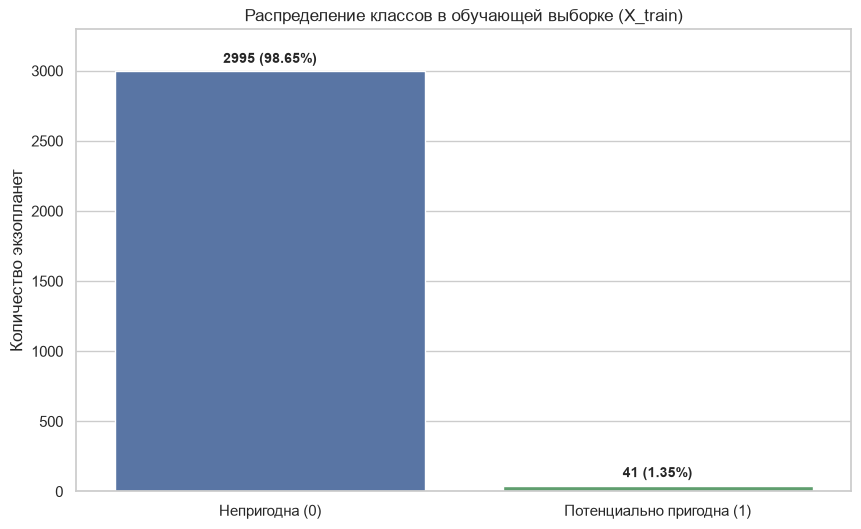

In [52]:
class_counts = y_train.value_counts().sort_index()
class_pct = (y_train.value_counts(normalize=True).sort_index() * 100).round(2)

plt.figure(figsize=(10,6))
ax = sns.barplot(
    x = ['Непригодна (0)', 'Потенциально пригодна (1)'],
    y = class_counts.values,
    palette = ['#4C72B0', '#55A868']
)

for i, (cnt, pct) in enumerate(zip(class_counts.values, class_pct.values)):
    ax.text(i, cnt + 40, f'{cnt} ({pct}%)', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.title('Распределение классов в обучающей выборке (X_train)', fontsize=12)
plt.ylabel('Количество экзопланет')
plt.ylim(0, class_counts.max() * 1.1)

plt.show()

* Наблюдается **экстремальный дисбаланс классов**: мажоритарный класс (непригодные планеты) составляет **98.65%** выборки, в то время как миноритарный — всего **1.35%** (41 планета в обучающей выборке).
* Тривиальный классификатор, присваивающий всем объектам класс `0`, формально получил бы точность $Accuracy = 98.65\%$, будучи абсолютно бесполезным на практике. 
* Оптимизация и оценка моделей должны опираться исключительно на метрики, чувствительные к миноритарному классу: **$Recall$ (полнота обнаружения)**, **$Precision$** и интегральные метрики **$F_1\text{-score}$** и **PR-AUC**.

#### 3.2. Основные характеристики для числовых и категориальных величин.

In [53]:
# Выберем ключевые физические параметры планеты и звезды
core_numeric = [
    'P_MASS',
    'P_RADIUS',
    'P_PERIOD',
    'P_SEMI_MAJOR_AXIS',
    'P_TEMP_EQUIL',
    'P_FLUX',
    'S_TEMPERATURE',
    'S_MASS',
    'S_RADIUS',
    'S_LUMINOSITY',
]

core_numeric = [col for col in core_numeric if col in X_train.columns]

print('Основные числовые характеристики ключевых параметров:')
display(X_train[core_numeric].describe().T)

# Характеристики категориальных признаков
core_categorical = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
if core_categorical:
    print('\nХарактеристики категориальных признаков:')
    display(X_train[core_categorical].describe().T)

Основные числовые характеристики ключевых параметров:


,count,mean,std,min,25%,50%,75%,max
P_MASS,1199.0,803.379353,1450.606293,1.906968e-02,26.071431,266.975520,823.174530,17668.0590
P_RADIUS,2357.0,4.256794,4.910756,3.363000e-01,1.580610,2.331680,3.575990,77.3490
P_PERIOD,2957.0,524.460719,10843.615073,9.070629e-02,4.487589,11.523100,40.990399,555530.0000
P_SEMI_MAJOR_AXIS,1784.0,7.358490,90.146065,4.400000e-03,0.057000,0.117000,0.538250,2500.0000
P_TEMP_EQUIL,2792.0,807.423816,458.814478,3.706760e+00,474.945628,740.782050,1060.642350,7056.7757
P_FLUX,2792.0,586.445189,11196.232029,4.481240e-08,12.148679,71.760808,302.729490,588634.3700
S_TEMPERATURE,2885.0,5507.615539,1898.599142,5.805000e+02,5040.000000,5599.000000,5931.000000,57000.0000
S_MASS,2445.0,1.003235,0.694892,1.000000e-02,0.810000,0.960000,1.120000,23.5600
S_RADIUS,2793.0,1.511820,3.705242,1.000000e-02,0.790000,0.970000,1.250000,71.2300
S_LUMINOSITY,2841.0,5.617265,47.371746,1.060541e-06,0.412630,0.898842,1.830597,1486.8958



Характеристики категориальных признаков:


C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\871750554.py:21: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  core_categorical = X_train.select_dtypes(include=['object', 'category']).columns.tolist()


,count,unique,top,freq
P_DETECTION,3036,10,Transit,2334
S_TYPE_TEMP,2936,7,G,1333


### Расшифровка и физический смысл ключевых параметров

Именование в каталоге строится по единому правилу:
* Префикс **`P_`** — свойства планеты (Planet). Обычно измеряются относительно Земли.
* Префикс **`S_`** — свойства родительской звезды (Star / Stellar). Измеряются относительно Солнца.

#### Параметры экзопланеты (`P_*`)

* **`P_MASS`** (*Planet Mass*) — **Масса планеты** (в массах Земли).  
  Показывает, во сколько раз планета тяжелее Земли. Определяет способность удерживать атмосферу и силу поверхностной гравитации.
* **`P_RADIUS`** (*Planet Radius*) — **Радиус планеты** (в радиусах Земли).  
  Физический размер. Позволяет разделить каменистые планеты земного типа  и газовые мини-нептуны.
* **`P_PERIOD`** (*Planet Orbital Period*) — **Орбитальный период** (в земных сутках).  
  Продолжительность «года» на планете — время одного полного оборота вокруг своей звезды.
* **`P_SEMI_MAJOR_AXIS`** (*Planet Semi-Major Axis*) — **Большая полуось орбиты** (в а.е. — астрономических единицах).  
  Геометрический радиус орбиты / среднее расстояние от планеты до звезды ($1\text{ а.е.} \approx$ расстояние от Земли до Солнца).
* **`P_TEMP_EQUIL`** (*Planet Equilibrium Temperature*) — **Равновесная температура** (в Кельвинах, К).  
  Теоретическая температура поверхности в предположении, что планета поглощает и переизлучает тепло как абсолютно черное тело (без учета парникового эффекта атмосферы). Для жидкой воды оптимальный диапазон: $\approx 200–320\text{ К}$.
* **`P_FLUX`** (*Planet Insolation Flux*) — **Поток излучения (инсоляция)** (в долях от земного потока).  
  Количество лучистой энергии звезды, падающей на единицу площади планеты (у Земли $= 1.0$).
* **`P_DETECTION`** (*Planet Detection Method*) — **Метод обнаружения планеты** (категориальный).  
  Каким именно астрономическим способом была открыта планета.


#### Параметры родительской звезды (`S_*`)

* **`S_TEMPERATURE`** (*Stellar Effective Temperature*) — **Эффективная температура звезды** (в Кельвинах, К).  
  Температура поверхности («фотосферы») звезды. Определяет ее спектральный класс и цвет (холодные красные карлики $\sim 3000\text{ К}$, Солнце $\sim 5800\text{ К}$, горячие белые звезды $> 7500\text{ К}$).
* **`S_MASS`** (*Stellar Mass*) — **Масса звезды** (в массах Солнца).  
  Фундаментальный параметр: определяет силу гравитации звезды, время ее жизни и скорость термоядерных реакций.
* **`S_RADIUS`** (*Stellar Radius*) — **Радиус звезды** (в радиусах Солнца).  
  Физический размер звезды относительно нашего Солнца.
* **`S_LUMINOSITY`** (*Stellar Luminosity*) — **Борометрическая светимость** (в светимостях Солнца).  
  Полная мощность электромагнитного излучения звезды во всех диапазонах. От светимости напрямую зависит, насколько далеко от звезды находится зона обитаемости.
* **`S_TYPE_TEMP`** (*Stellar Spectral Temperature Class*) — **Спектральный класс звезды** (категориальный).  
  Буквенная гарвардская классификация звезд по температуре фотосферы.

---

* Колоссальный разброс масштабов: Средние значения астрофизических величин превосходят медианы (50%-квантиль). Например, масса планеты `P_MASS` имеет медиану порядка единиц/десятков масс Земли, но максимальные значения достигают десятков тысяч (тяжелые газовые гиганты и субкоричневые карлики).
* Сверхвысокие стандартные отклонения: Это свидетельствует о выраженном степенном характере физических распределений в космосе (тяжелые хвосты).

#### 3.3. Анализ формы распределений признаков (гистограммы и необходимость логарифмирования).


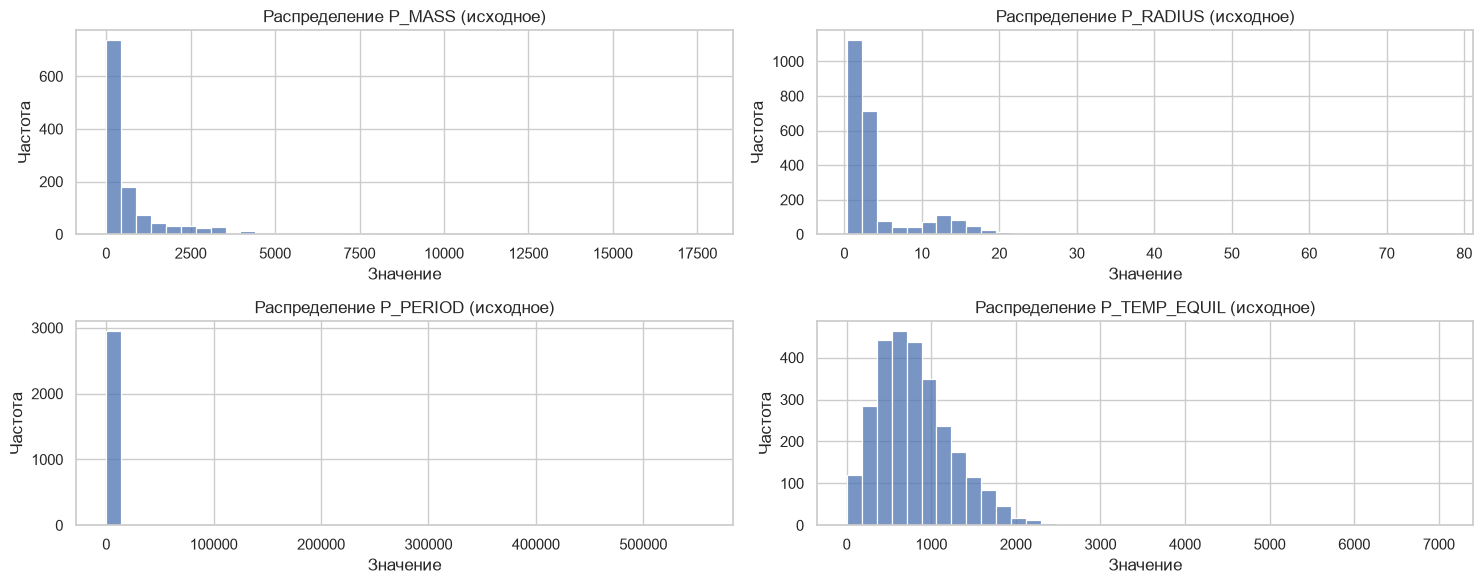

Коэффициенты ассиметрии в исходном масштабе:
P_MASS           3.912778
P_RADIUS         3.160277
P_PERIOD        46.806810
P_TEMP_EQUIL     1.652025
dtype: float64


In [54]:
# Гистограммы в исходном масштабе
plt.figure(figsize=(15, 6))

for i, col in enumerate(['P_MASS', 'P_RADIUS', 'P_PERIOD', 'P_TEMP_EQUIL'][:4], 1):
    plt.subplot(2, 2, i)
    sns.histplot(X_train[col].dropna(), bins=40, color='#4C72B0')
    plt.title(f'Распределение {col} (исходное)')
    plt.xlabel('Значение')
    plt.ylabel('Частота')

plt.tight_layout()
plt.show()

# Оценка коэффициента ассиметрии
print('Коэффициенты ассиметрии в исходном масштабе:')
print(X_train[['P_MASS', 'P_RADIUS', 'P_PERIOD', 'P_TEMP_EQUIL']].skew())

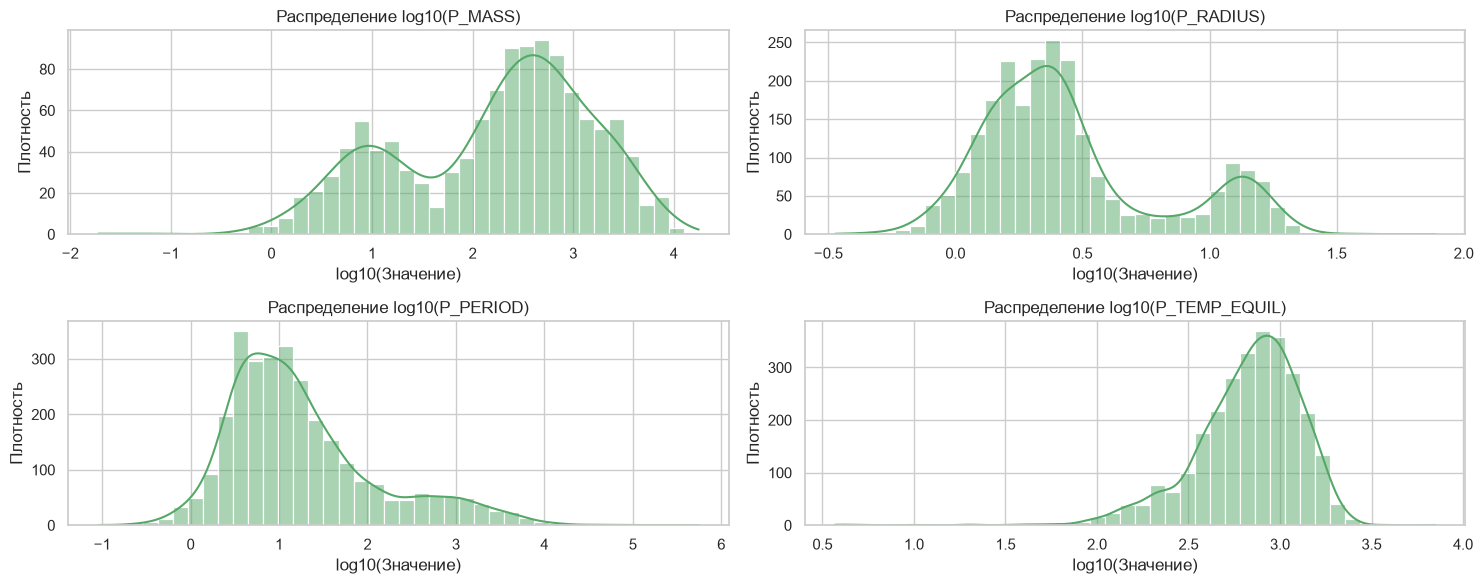

In [55]:
# Гистограммы после логарифмирования log10(x)
plt.figure(figsize=(15, 6))

for i, col in enumerate(['P_MASS', 'P_RADIUS', 'P_PERIOD', 'P_TEMP_EQUIL'][:4], 1):
    plt.subplot(2, 2, i)
    log_data = np.log10(X_train[col].dropna().loc[lambda x: x > 0])
    sns.histplot(log_data, bins=40, kde=True, color='#55A868')
    plt.title(f'Распределение log10({col})')
    plt.xlabel('log10(Значение)')
    plt.ylabel('Плотность')

plt.tight_layout()
plt.show()

* В исходном масштабе гистограммы демонстрируют экстремальный положительный скос (длинный правый хвост). Подавляющее число наблюдений спрессовано около нуля, а редкие гиганты растягивают ось абсцисс.
* Применение логарифмического преобразования переводит степенные и мультипликативные астрофизические величины в квазинормальные, колоколообразные распределения.
* В распределении радиуса `log10(P_RADIUS)` отчетливо видна бимодальность (знаменитый «радиусный провал Фултона» в экзопланетологии, разделяющий каменистые суперземли и газовые мини-нептуны). Логарифмирование критически важно для корректной работы евклидовой метрики в k-NN.

#### 3.4. Распределение признаков по классам (ящики с усами).

Ящики с усами строим отдельно для каждого класса `Target` (0 — непригодна, 1 — потенциально пригодна): так наглядно видно, какие физические параметры разделяют классы, а какие перекрываются. Для признаков с тяжелыми хвостами используем десятичный логарифм $\log_{10}$. Точки за «усами» — физические экстремумы (планеты-гиганты, ультракороткопериодические орбиты).

C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\4086355158.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\4086355158.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\4086355158.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\4086355158.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` va

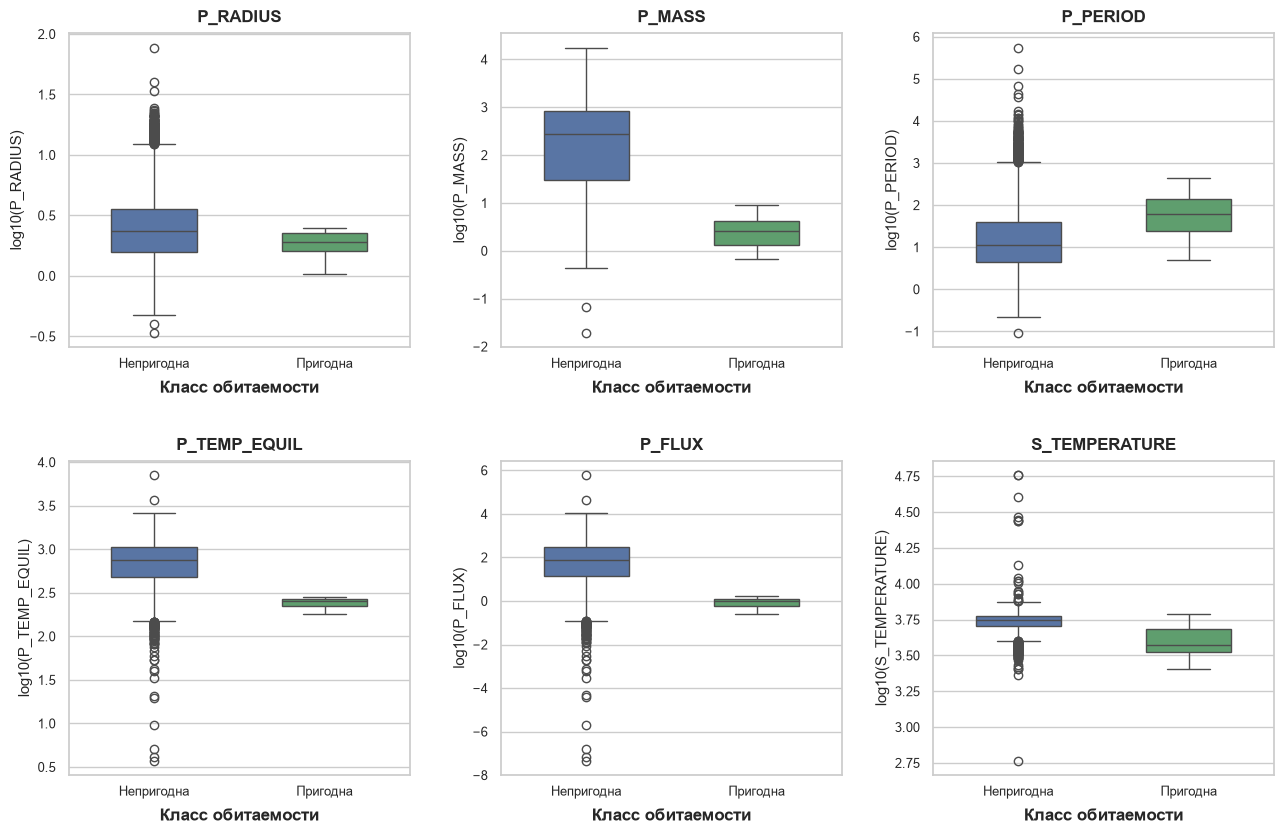

In [56]:
# Создание объединенного датафрейма для визуализации
df_train = X_train.copy()
df_train['Target'] = y_train.map({0: 'Непригодна', 1: 'Пригодна'})
order = ['Непригодна', 'Пригодна']

# Выбор ключевых параметров планеты и звезды
cols_for_box = [
    'P_RADIUS',
    'P_MASS',
    'P_PERIOD',
    'P_TEMP_EQUIL',
    'P_FLUX',
    'S_TEMPERATURE',
]

cols_for_box = [c for c in cols_for_box if c in df_train.columns]

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5))

for ax, col in zip(axes.ravel(), cols_for_box):
    # Фильтрация строго положительных значений для корректного логарифмирования
    sub_df = df_train[df_train[col] > 0][[col, 'Target']].dropna()

    # Логарифмирование величин со степенным разбросом
    values = np.log10(sub_df[col])
    ylabel = f'log10({col})'

    sns.boxplot(
        x='Target',
        y=values,
        data=sub_df,
        order=order,
        palette=['#4C72B0', '#55A868'],
        width=0.5,  # ящики чуть аккуратнее по ширине
        ax=ax,
    )

    ax.set_title(col, fontsize=12, fontweight='bold', pad=8)
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.set_xlabel('Класс обитаемости', fontsize=12, fontweight='bold', labelpad=7)
    ax.tick_params(axis='x', labelsize=9.5, pad=1.5)
    ax.tick_params(axis='y', labelsize=9.5)

plt.tight_layout(h_pad=2.5, w_pad=2.0)  # увеличиваем расстояние между графиками
plt.show()

* `P_TEMP_EQUIL` и `P_FLUX` — **наиболее сильные признаки**: у пригодных планет разброс минимален. Их межквартильные интервалы практически не перекрываются с классом `Непригодна`.
* `P_MASS` и `P_RADIUS` — задают **жесткую верхнюю границу**, позволяющую надежно отсекает газовые гиганты. Перекрытие снизу связано с бесплодными каменистыми планетами.
* `P_PERIOD` — медианный «год» у пригодных планет существенно дольше ($\approx 50–100$ суток против $\approx 10$ суток у непригодных), поскольку класс `Непригодна` переполнен близкими к звездам «горячими» мирами.
* `S_TEMPERATURE` — родительские звезды пригодных планет холоднее (медиана $\approx 3500–4500\text{ К}$, оранжевые и красные карлики), тогда как непригодные планеты открыты преимущественно у более горячих солнцеподобных звезд ($\approx 5500–6000\text{ К}$).
* **Выбросы:** длинные хвосты точек в классе `Непригодна` — это не ошибки, а реальные физические экстремумы (супергиганты). Логарифмирование успешно сжало эти шкалы, исключив искажение расстояний в $k$-NN.

#### 3.5. Анализ многомерных взаимосвязей (диаграммы рассеяния и фазовые диаграммы).

Построим диаграммы для ключевых физических пар с раскраской по классам (в логарифмическом масштабе) и матрицу всех парных диаграмм на подвыборке.

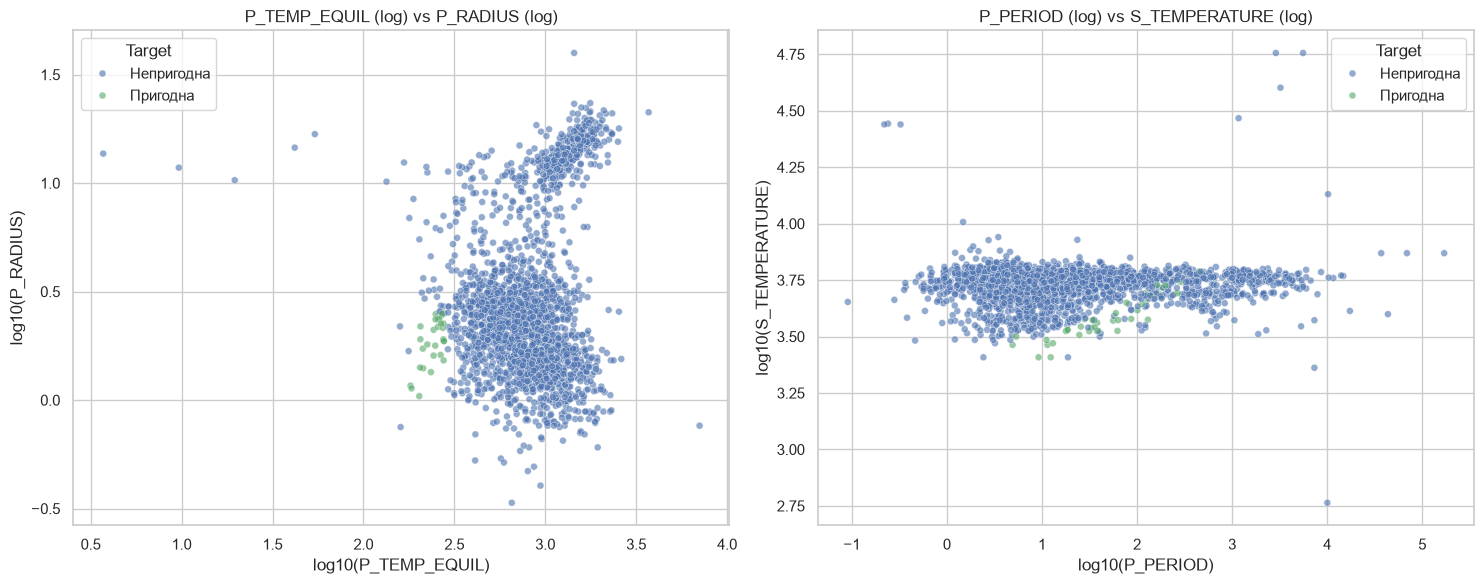

In [57]:
# Формирование логарифмированных признаков для визуализации и последующего анализа
plot_df = df_train.copy()
log_cols = ['P_RADIUS', 'P_TEMP_EQUIL', 'P_PERIOD', 'S_TEMPERATURE']

for col in log_cols:
    if col in plot_df.columns:
        plot_df[col + '_log'] = np.log10(
            plot_df[col].replace(0, np.nan).dropna()
        )

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=plot_df,
    x='P_TEMP_EQUIL_log',
    y='P_RADIUS_log',
    hue='Target',
    hue_order=order,
    palette=['#4C72B0', '#55A868'],
    alpha=0.6,
    s=25,
    ax=axes[0]
)

axes[0].set_title('P_TEMP_EQUIL (log) vs P_RADIUS (log)')
axes[0].set_xlabel('log10(P_TEMP_EQUIL)')
axes[0].set_ylabel('log10(P_RADIUS)')

sns.scatterplot(
    data=plot_df,
    x='P_PERIOD_log',
    y='S_TEMPERATURE_log',
    hue='Target',
    hue_order=order,
    palette=['#4C72B0', '#55A868'],
    alpha=0.6,
    s=25,
    ax=axes[1]
)

axes[1].set_title('P_PERIOD (log) vs S_TEMPERATURE (log)')
axes[1].set_xlabel('log10(P_PERIOD)')
axes[1].set_ylabel('log10(S_TEMPERATURE)')

plt.tight_layout()
plt.show()

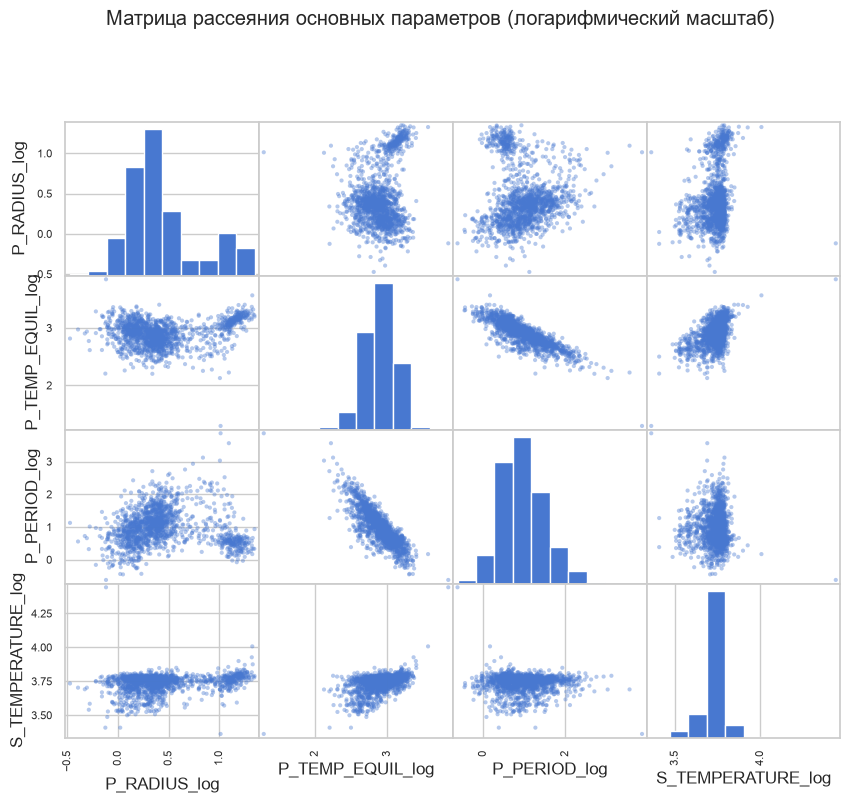

In [58]:
# Матрица диаграмм рассеяния, построенная на подвыборке
cols_sm = [
    'P_RADIUS_log',
    'P_TEMP_EQUIL_log',
    'P_PERIOD_log',
    'S_TEMPERATURE_log',
]

cols_sm = [c for c in cols_sm if c in plot_df.columns]

sample_df = plot_df[cols_sm].dropna().sample(min(1500, len(plot_df)), random_state=RANDOM_STATE)

pd.plotting.scatter_matrix(
    sample_df,
    figsize=(10, 8),
    alpha=0.4,
    diagonal='hist'
)
plt.suptitle('Матрица рассеяния основных параметров (логарифмический масштаб)', y=1.02)
plt.show()

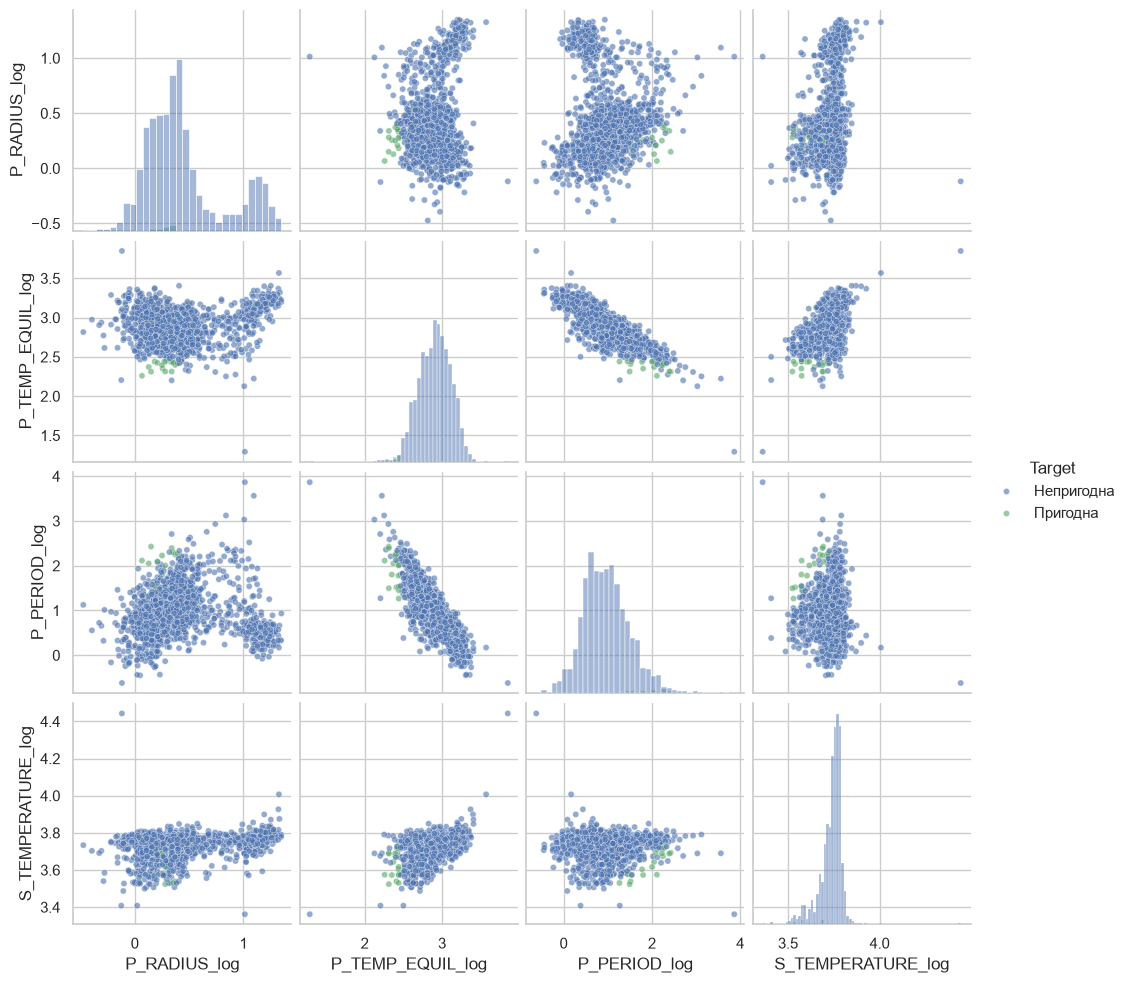

In [59]:
# Парные диаграммы с разделением по классам обитаемости
pair_cols = cols_sm + ['Target']
sample_pair = (
    plot_df[pair_cols].dropna().sample(min(1500, len(plot_df)), random_state=RANDOM_STATE)
)

sns.pairplot(
    sample_pair,
    hue='Target',
    hue_order=order,
    palette=['#4C72B0', '#55A868'],
    diag_kind='hist',
    plot_kws={'alpha': 0.6, 's': 20}
)

plt.show()

* **Локализация целевого класса:** На диаграмме `P_TEMP_EQUIL (log)` vs `P_RADIUS (log)` потенциально обитаемые миры образуют компактный обособленный кластер на нижней границе основного распределения ($\log_{10}(\text{P\_TEMP\_EQUIL}) \approx 2.3–2.5$, $\log_{10}(\text{P\_RADIUS}) \approx 0.0–0.35$). Они ограничены как по температуре (коридор жидкой воды), так и по размеру (отсечение газовых гигантов).
* **Физическая связь Звезда — Период:** На диаграмме `P_PERIOD (log)` vs `S_TEMPERATURE (log)` для класса `Пригодна` виден восходящий наклон: у холодных красных карликов ($\log_{10} \approx 3.5$) зона обитаемости находится близко к звезде (период $\approx 10–30$ дней), тогда как у более горячих солнцеподобных звезд ($\log_{10} \approx 3.75$) период сдвигается к $100–300$ дням.
* **Взаимосвязь параметров в pairplot:** На графике `P_PERIOD` vs `P_TEMP_EQUIL` наблюдается четкая обратная зависимость: с ростом орбитального периода равновесная температура монотонно падает, а пригодные планеты занимают строго определенный участок этой полосы.
* **Форма распределений на диагонали:** После логарифмирования гистограммы перешли к унимодальным и бимодальным колоколообразным формам. В распределении `P_RADIUS_log` отчетливо виден правый горб ($\log_{10} \approx 0.8–1.0$), соответствующий популяции газовых гигантов.
* **Сложность границы классов:** Класс `Пригодна` не отделим линейно ни в одной проекции — это замкнутая локальная область параметров, что делает метрический алгоритм $k$-NN естественным кандидатом для решения задачи.

#### 3.6. Исследование коллинеарности (корреляционная матрица).

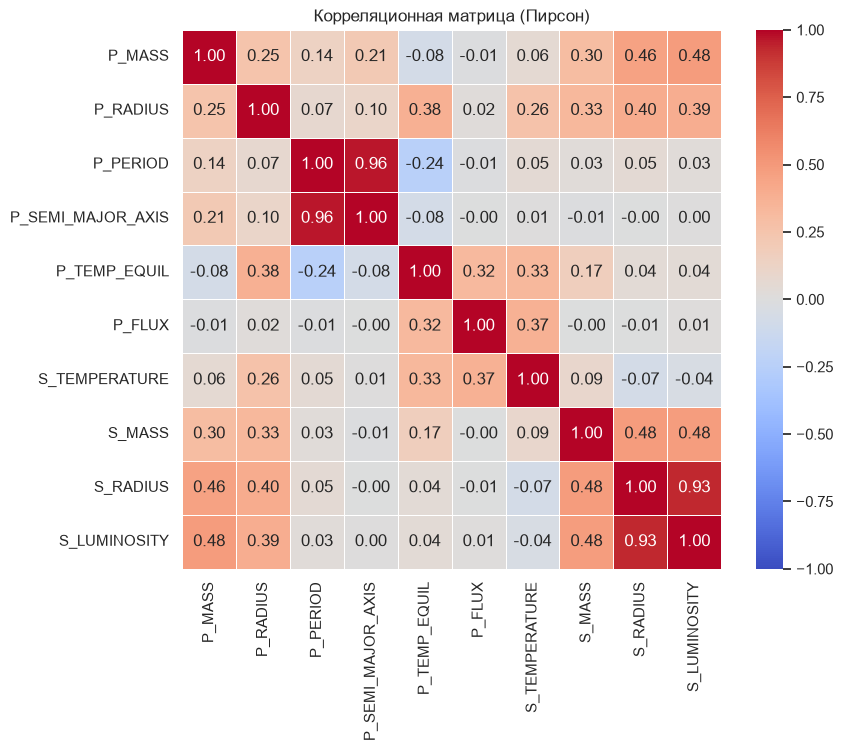

In [60]:
corr = df_train[core_numeric].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title('Корреляционная матрица (Пирсон)')
plt.show()

In [61]:
# Пары признаков с корреляцией |корреляцией| > 0.5
corr.where(np.triu(np.abs(corr) > 0.5, k=1)).stack().sort_values(ascending=False)

P_PERIOD      P_SEMI_MAJOR_AXIS    0.963516
S_RADIUS      S_LUMINOSITY         0.931762
P_MASS        P_MASS                    NaN
              P_RADIUS                  NaN
              P_PERIOD                  NaN
                                     ...   
S_LUMINOSITY  P_FLUX                    NaN
              S_TEMPERATURE             NaN
              S_MASS                    NaN
              S_RADIUS                  NaN
              S_LUMINOSITY              NaN
Length: 100, dtype: float64

* **Критическая коллинеарность ($|r| > 0.9$):** порог сильной корреляции преодолели строго две пары:
  * `P_PERIOD` и `P_SEMI_MAJOR_AXIS` ($r = 0.96$): прямое отражение **3-го закона Кеплера** ($T^2 \propto a^3$). Период обращения и большая полуось орбиты физически дублируют друг друга.
  * `S_RADIUS` и `S_LUMINOSITY` ($r = 0.93$): связь радиуса и полной мощности излучения звезды ($L \propto R^2 T^4$). Радиус родительской звезды вносит решающий вклад в её светимость.
* **Умеренная связь параметров звезды ($r = 0.48$):** `S_MASS` умеренно коррелирует с `S_RADIUS` и `S_LUMINOSITY` ($r = 0.48$), что согласуется с теорией строения звезд главной последовательности (более массивные звезды крупнее и ярче).
* **Специфика линейной корреляции Пирсона для нелинейных законов:**
  * `P_TEMP_EQUIL` и `P_FLUX` показали корреляцию лишь $r = 0.32$, несмотря на строгую физическую связь (закон Стефана — Больцмана $F \propto T^4$). Линейный коэффициент Пирсона чувствителен к выбросам и занижает нелинейные степенные зависимости.
  * `P_MASS` и `P_RADIUS` имеют слабую линейную связь ($r = 0.25$). Это объясняется колоссальной разницей плотностей: от плотных каменистых суперземель до рыхлых «горячих юпитеров» с раздутыми атмосферами.
* **Взаимосвязь орбиты и климата:** ожидаемо отрицательная корреляция между `P_PERIOD` и `P_TEMP_EQUIL` ($r = -0.24$) — чем длиннее орбита и дальше планета от звезды, тем ниже температура её поверхности.
* **Влияние на модель ($k$-NN):** Пары `(P_PERIOD, P_SEMI_MAJOR_AXIS)` и `(S_RADIUS, S_LUMINOSITY)` являются почти полными дубликатами. В метрических алгоритмах такое дублирование искусственно удваивает вес соответствующего физического измерения при расчете расстояний. Эти избыточные признаки станут главными кандидатами на исключение.

#### 3.7. Анализ категориальных признаков и их связи с обитаемостью.

Для категориальных признаков `P_DETECTION` (метод обнаружения) и `S_TYPE_TEMP` (спектральный класс звезды) смотрим, как распределены классы внутри каждой категории.


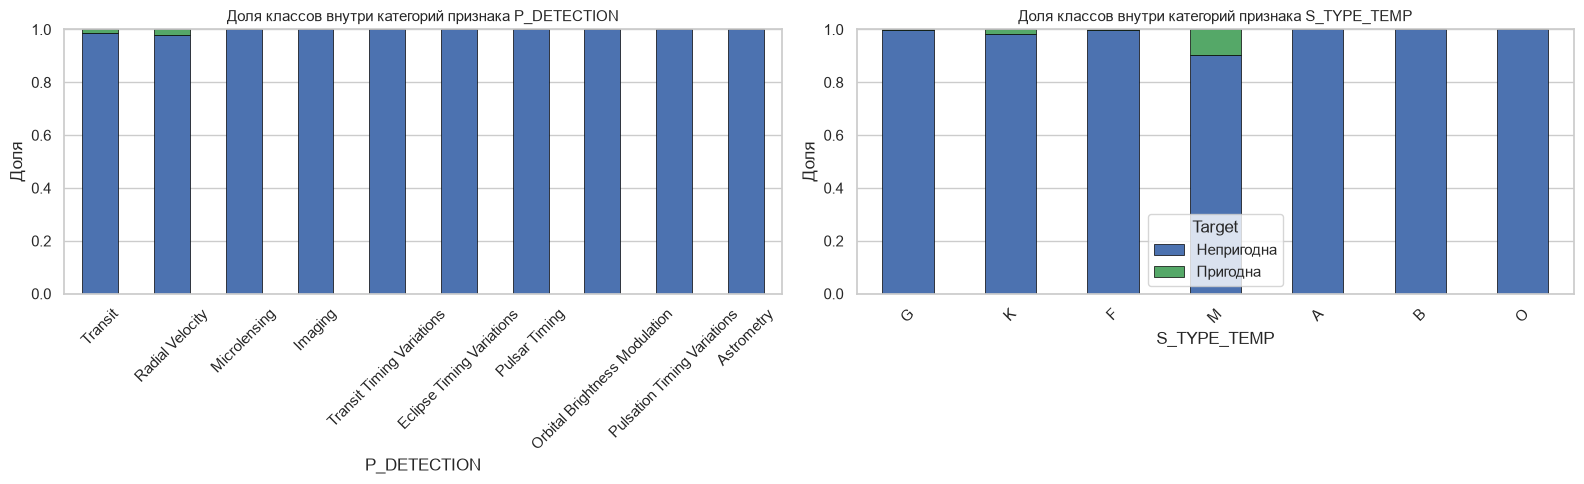

Процент пригодных планет (класс "Пригодна") внутри категорий:

Признак P_DETECTION:
P_DETECTION
Radial Velocity                  2.09
Transit                          1.24
Eclipse Timing Variations        0.00
Astrometry                       0.00
Imaging                          0.00
Microlensing                     0.00
Pulsar Timing                    0.00
Orbital Brightness Modulation    0.00
Pulsation Timing Variations      0.00
Transit Timing Variations        0.00
Name: Пригодна, dtype: float64

Признак S_TYPE_TEMP:
S_TYPE_TEMP
M    9.84
K    1.54
G    0.30
F    0.18
A    0.00
B    0.00
O    0.00
Name: Пригодна, dtype: float64


In [62]:
# Ключевые информативные категориальные признаки
cat_cols = ['P_DETECTION', 'S_TYPE_TEMP']
cat_cols = [c for c in cat_cols if c in df_train.columns]

fig, axes = plt.subplots(1, len(cat_cols), figsize=(16, 5))
if len(cat_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, cat_cols):
    # Нормированная таблица сопряженности (доли классов внутри каждой категории)
    ct = pd.crosstab(df_train[col], df_train['Target'], normalize='index')[order]

    category_order = df_train[col].value_counts().index
    ct = ct.reindex(category_order).dropna()

    ct.plot(
        kind='bar',
        stacked=True,
        ax=ax,
        color=['#4C72B0', '#55A868'],
        legend=(col == cat_cols[-1]),
        edgecolor='black',
        linewidth=0.5
    )

    ax.set_title(f'Доля классов внутри категорий признака {col}', fontsize=11)
    ax.set_ylabel('Доля')
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print('Процент пригодных планет (класс "Пригодна") внутри категорий:')
for col in cat_cols:
    ct_pct = (
        pd.crosstab(df_train[col], df_train['Target'], normalize='index')['Пригодна'] * 100
    ).round(2)
    print(f'\nПризнак {col}:')
    print(ct_pct.sort_values(ascending=False))

* **`P_DETECTION` (метод открытия):** 
  * Пригодные планеты обнаружены **строго двумя методами**: методом лучевых скоростей (**Radial Velocity** — $2.09\%$) и транзитным методом (**Transit** — $1.24\%$). 
  * Все остальные 8 методов (Microlensing, Imaging, тайминг пульсаров и затмений) дают ровно **$0.00\%$**. Это чисто инструментальный эффект: методы прямого наблюдения и микролинзирования нацелены на удаленные газовые гиганты и физически не способны регистрировать небольшие планеты земного типа.
* **`S_TYPE_TEMP` (спектральный класс звезды):** 
  * Наблюдается колоссальный контраст: для холодных красных карликов **класса M** доля потенциально обитаемых планет составляет **$9.84\%$** (почти каждая десятая планета!). На графике это отражено крупным зеленым сегментом.
  * Для оранжевых карликов **класса K** эта доля снижается до **$1.54\%$**, а у солнцеподобных звезд **класса G** составляет всего **$0.30\%$** (менее одной трети процента). 
  * У массивных горячих звезд (**A, B, O**) пригодных миров нет (**$0.00\%$**), так как они живут слишком мало для формирования условий жизни и излучают губительный ультрафиолет. 
  * Доминирование M-карликов обусловлено наблюдательной селекцией телескопа Kepler: зона жизни у холодных звезд расположена вплотную к светилу, поэтому планеты совершают обороты за дни/недели, вызывая частые транзиты, которые легче всего детектировать.

### 4. Выбросы и невалидные значения

Необычные значения в данных делятся на две принципиальные категории:
* **Невалидные значения (ошибки):** физически невозможные или абсурдные значения (например, отрицательная масса планеты, нулевой радиус, отрицательная температура). Их необходимо исправить или удалить.
* **Выбросы (экстремумы):** редкие, но реальные физические значения (например, планеты-гиганты с массой в тысячи масс Земли). Они несут ценную информацию о хвостах астрофизического распределения, поэтому слепо выбрасывать их нельзя.

Правила проверки невалидных значений не используют статистику по обучающей выборке, поэтому применяются одинаково к тренировочному и тестовому наборам. Сначала проверим данные на наличие физических аномалий.

#### Проверка жестких физических ограничений (Hard Bounds)

In [63]:
# Создание копии для экспериментов с очисткой
df_train = X_train.copy()
df_test = X_test.copy()

# Проверка ключевых параметров на физически невозможные значения (<=0)
check_cols = ['P_MASS', 'P_RADIUS', 'P_PERIOD', 'S_TEMPERATURE', 'S_MASS']
for c in check_cols:
    if c in df_train.columns:
        print(
            f'Колонка {c:15} | Минимум: {df_train[c].min():10.3f} | '
            f'Отрицательных значений / Нулей: {(df_train[c] <= 0).sum()}'
        )

Колонка P_MASS          | Минимум:      0.019 | Отрицательных значений / Нулей: 0
Колонка P_RADIUS        | Минимум:      0.336 | Отрицательных значений / Нулей: 0
Колонка P_PERIOD        | Минимум:      0.091 | Отрицательных значений / Нулей: 0
Колонка S_TEMPERATURE   | Минимум:    580.500 | Отрицательных значений / Нулей: 0
Колонка S_MASS          | Минимум:      0.010 | Отрицательных значений / Нулей: 0


**Результаты проверки и стратегия обработки:**
1. **Невалидные значения:** В физических параметрах экзопланет значения $\le 0$ (нулевые или отрицательные радиусы/массы) являются физически невозможными аномалиями датчиков или ошибками занесения в каталог. Такие записи заменяются на `NaN`, чтобы корректно обработать их далее.
2. **Выбросы (хвосты распределений):** Экстремальные значения (например, массивные газовые гиганты) **не удаляются**. Это реальные объекты нашей вселенной. 
3. **Борьба с влиянием хвостов в $k$-NN:** Поскольку алгоритм $k$-NN базируется на вычислении евклидовых расстояний, гигантские выбросы могли бы исказить метрику. Эту проблему мы нейтрализуем ранее обоснованным **логарифмированием ($\log_{10}$)** и последующей **стандартизацией (`StandardScaler`)**.

In [64]:
def fix_invalid_astro(df):
    d = df.copy()
    for col in check_cols:
        if col in d.columns:
            d.loc[d[col] <= 0, col] = np.nan
    return d

df_train = fix_invalid_astro(df_train)
df_test = fix_invalid_astro(df_test)
print('Невалидные физические значения успешно заменены на NaN.')

Невалидные физические значения успешно заменены на NaN.


### 5. Обработка пропущенных значений

В астрономических каталогах пропуски (`NaN`) — стандартное явление. Они возникают из-за ограничений методов наблюдения: например, транзитный метод дает точный радиус (`P_RADIUS`), но не позволяет измерить массу (`P_MASS`), а метод лучевых скоростей — наоборот.

**Стратегия отбора признаков:**
* Удаляем столбцы с критически высокой долей пропусков (более $70\%$ по обучающей выборке), так как они не несут полезной информации.
* Удаляем константные признаки (где все значения одинаковы)

In [65]:
# Вычисляем процент пропусков в train и test
miss = pd.DataFrame({
    'train, %': df_train.isna().mean() * 100,
    'test, %': df_test.isna().mean() * 100,
}).round(2)

print('Колонки с наибольшей долей пропусков:')
print(miss[miss['train, %'] > 0].sort_values('train, %', ascending=False).head(10))

# Фильтрация: оставляем признаки, где пропусков <= 70% и признак не константный
cols_keep = [
    c
    for c in df_train.columns
    if miss.loc[c, 'train, %'] <= 70 and df_train[c].nunique(dropna=True) > 1
]

print(f'\nИсходное число признаков: {df_train.shape[1]}')
print(f'Удалено из-за пропусков (>70%) или константности: {df_train.shape[1] - len(cols_keep)}')
print(f'Осталось признаков для работы: {len(cols_keep)}')

# Фильтрация датасетов
X_train = df_train[cols_keep].copy()
X_test = df_test[cols_keep].copy()

Колонки с наибольшей долей пропусков:
                        train, %  test, %
P_DETECTION_RADIUS        100.00   100.00
S_MAGNETIC_FIELD          100.00   100.00
S_DISC                    100.00   100.00
P_DETECTION_MASS          100.00   100.00
P_GEO_ALBEDO              100.00   100.00
P_ATMOSPHERE              100.00   100.00
P_GEO_ALBEDO_ERROR_MIN     99.87    99.90
P_GEO_ALBEDO_ERROR_MAX     99.87    99.90
P_TEMP_MEASURED            99.87    99.90
P_TPERI_ERROR_MAX          88.50    87.85

Исходное число признаков: 94
Удалено из-за пропусков (>70%) или константности: 24
Осталось признаков для работы: 70


**Стратегия заполнения пропусков:**
Все параметры для заполнения вычисляются **строго по обучающей выборке (`train`)** и затем применяются к тестовой (`test`), что исключает утечку данных (Data Leakage):
1. **Числовые признаки:** заполняются **медианой** (`strategy='median'`). Использование среднего здесь недопустимо из-за тяжелых хвостов и выбросов, к которым медиана устойчива.
2. **Категориальные признаки:** заполняются **модой** (самым частым значением, `strategy='most_frequent'`).
3. **Индикаторы пропусков:** Для ключевых физических параметров (например, массы или радиуса) сам факт наличия пропуска может нести скрытую закономерность (например, планеты определенного типа реже поддаются измерению масс). Создадим бинарные флаги пропущенных значений (`_missing`), чтобы модель учитывала этот факт.

In [66]:
from sklearn.impute import SimpleImputer

# Выделение типов оставшихся признаков
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(
    include=['object', 'category', 'string']
).columns.tolist()

# Создание индикаторов пропусков для ключевых физических колонок, где пропусков много
key_missing_cols = ['P_MASS', 'P_RADIUS', 'P_TEMP_EQUIL']
for col in key_missing_cols:
    if col in X_train.columns:
        X_train[col + '_missing'] = X_train[col].isna().astype(int)
        X_test[col + '_missing'] = X_test[col].isna().astype(int)

# Заполнение числовых признаков медианой
imp_num = SimpleImputer(missing_values=np.nan, strategy='median')
imp_num.fit(X_train[num_cols])

X_train[num_cols] = imp_num.transform(X_train[num_cols])
X_test[num_cols] = imp_num.transform(X_test[num_cols])

# Заполнение категориальных признаков модой
if cat_cols:
    imp_cat = SimpleImputer(missing_values=np.nan, strategy='most_frequent')
    imp_cat.fit(X_train[cat_cols])

    X_train[cat_cols] = imp_cat.transform(X_train[cat_cols])
    X_test[cat_cols] = imp_cat.transform(X_test[cat_cols])

# Контрольная проверка пропусков
print(
    'Осталось пропусков в обучающей выборке:', X_train.isna().sum().sum()
)
print('Осталось пропусков в тестовой выборке:', X_test.isna().sum().sum())

Осталось пропусков в обучающей выборке: 0
Осталось пропусков в тестовой выборке: 0


### 6. Обработка категориальных признаков

Алгоритмы машинного обучения в библиотеке `scikit-learn` работают исключительно с числовыми матрицами, поэтому текстовые категориальные признаки необходимо закодировать. 

Простая порядковая нумерация категорий (например, присвоение меток $1, 2, 3 \dots$) для алгоритма $k$-NN неприменима: расстояние между несуществующими «числами» категорий исказило бы геометрические расстояния в пространстве признаков. 

Для корректного кодирования используется метод **бинаризации (One-Hot Encoding)**: каждая уникальная категория превращается в отдельный бинарный признак-индикатор, принимающий значения `0` или `1`.

В нашем датасете к категориальным признакам относятся:
* `P_DETECTION` — метод открытия экзопланеты;
* `S_TYPE_TEMP` — спектральный класс родительской звезды.

В ходе предварительной очистки и фильтрации все текстовые идентификаторы (`P_NAME`, `S_NAME`), константные и высококардинальные текстовые колонки с уникальными строками были удалены, так как они не несут обобщающей физической информации. В качестве полноценных категориальных факторов, пригодных для математического анализа и кодирования, остались только дискретные астрофизические характеристики: метод открытия (`P_DETECTION`) и спектральный класс звезды (`S_TYPE_TEMP`).

#### Анализ уникальных значений категориальных признаков

In [67]:
# Оценивание количества уникальных категорий и их распределение в обучающей выборке
for col in cat_cols:
    if col in X_train.columns:
        print(f'Признак: {col} | Уникальных категорий: {X_train[col].nunique()}')
        print(X_train[col].value_counts().head(10))
        print('-' * 40)

Признак: P_DETECTION | Уникальных категорий: 10
P_DETECTION
Transit                          2334
Radial Velocity                   573
Microlensing                       56
Imaging                            36
Transit Timing Variations          16
Eclipse Timing Variations          11
Pulsar Timing                       4
Orbital Brightness Modulation       4
Pulsation Timing Variations         1
Astrometry                          1
Name: count, dtype: int64
----------------------------------------
Признак: S_TYPE_TEMP | Уникальных категорий: 7
S_TYPE_TEMP
G    1433
K     781
F     549
M     244
A      16
B      10
O       3
Name: count, dtype: int64
----------------------------------------


#### Применение One-Hot Encoding

Для преобразования категорий в набор бинарных столбцов воспользуемся `OneHotEncoder`. 
* Параметр `handle_unknown='ignore'` гарантирует устойчивость модели: если в тестовой выборке (`X_test`) встретится редкая категория, которой не было в обучающей, кодировщик просто проигнорирует её, выставив во всех соответствующих dummy-столбцах нули, вместо того чтобы вызывать ошибку выполнения.
* Параметр `sparse_output=False` преобразует разреженную матрицу в стандартный массив NumPy.

In [68]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = [c for c in cat_cols if c in X_train.columns]

# Инициализация энкодера
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder.fit(X_train[cat_cols])

def encode_categorial_features(df, enc, cols):
    """Функция для безопасного кодирования категорий и слияния с датасетом"""
    # Превращение категории в бинарные столбцы 
    encoded_array = enc.transform(df[cols])
    encoded_df = pd.DataFrame(encoded_array, columns=enc.get_feature_names_out(cols), index=df.index)

    # Соединение исходного датасета (без старых категориальных столбцов) с закодированными столбцами
    res_df = pd.concat([df.drop(columns=cols), encoded_df], axis=1)
    return res_df

# Применение функции для трансформации к train и test
X_train = encode_categorial_features(X_train, encoder, cat_cols)
X_test = encode_categorial_features(X_test, encoder, cat_cols)

print(
    f'Размерность X_train после One-Hot Encoding: {X_train.shape[0]} строк,'
    f' {X_train.shape[1]} признаков'
)
print(
    f'Размерность X_test после One-Hot Encoding: {X_test.shape[0]} строк,'
    f' {X_test.shape[1]} признаков'
)
print(
    'Пропущенных значений после кодирования:',
    X_train.isna().sum().sum() + X_test.isna().sum().sum(),
)

Размерность X_train после One-Hot Encoding: 3036 строк, 88 признаков
Размерность X_test после One-Hot Encoding: 1012 строк, 88 признаков
Пропущенных значений после кодирования: 0


Категориальные признаки успешно переведены в числовой бинарный формат. Пространство признаков расширилось за счет новых бинарных признаков-индикаторов (теперь модель видит каждый метод обнаружения и спектральный класс звезды как независимую перпендикулярную ось). Все пропущенные значения на этапе кодирования полностью ликвидированы. Датасет готов к процедуре масштабирования.

### 7. Нормализация

Метод ближайших соседей ($k$-NN) и линейные модели определяют близость объектов с помощью евклидова расстояния. Это означает, что признаки с большими абсолютными значениями и дисперсией будут полностью доминировать над остальными. 

В выбранном каталоге масштабы физических величин различаются на астрономические порядки: масса планеты может составлять тысячи единиц, в то время как эксцентриситет орбиты всегда лежит в диапазоне от $0$ до $1$, а температура измеряется тысячами Кельвинов. Без нормализации расстояние между планетами определялось бы исключительно самыми «крупными» признаками.

#### Логарифмирование сильно скошенных признаков

In [69]:
skewed_num_cols = [
    'P_MASS',
    'P_RADIUS',
    'P_PERIOD',
    'P_SEMI_MAJOR_AXIS',
    'P_FLUX',
    'S_LUMINOSITY',
]

skewed_num_cols = [c for c in skewed_num_cols if c in X_train.columns]

print('Признаки до логарифмирования (пример min/max):')
print(X_train[skewed_num_cols].agg(['min', 'max']))

# Применяем log1p (логирование log(1+x), безопасное для нулей)
for df_obj in [X_train, X_test]:
  for col in skewed_num_cols:
    df_obj[col] = np.log1p(df_obj[col])

print(
    '\nПризнаки после логарифмирования log1p (пример min/max):'
)
print(X_train[skewed_num_cols].agg(['min', 'max']))

Признаки до логарифмирования (пример min/max):
          P_MASS  P_RADIUS       P_PERIOD  P_SEMI_MAJOR_AXIS        P_FLUX  \
min      0.01907    0.3363       0.090706             0.0044  4.481240e-08   
max  17668.05900   77.3490  555530.000000          2500.0000  5.886344e+05   

     S_LUMINOSITY  
min      0.000001  
max   1486.895800  

Признаки после логарифмирования log1p (пример min/max):
      P_MASS  P_RADIUS   P_PERIOD  P_SEMI_MAJOR_AXIS        P_FLUX  \
min  0.01889  0.289905   0.086825           0.004390  4.481239e-08   
max  9.77957  4.361173  13.227680           7.824446  1.328556e+01   

     S_LUMINOSITY  
min      0.000001  
max      7.305118  


#### Стандартизация

In [70]:
from sklearn.preprocessing import StandardScaler

# Нахождение всех непрерывных числовых признаков, которые требуют стандартизации
cols_to_scale = [
    c
    for c in X_train.select_dtypes(include=[np.number]).columns
    if not c.endswith('_missing') and X_train[c].nunique() > 2
]

# Инициализация и обучение скейлера строго на обучающей выборке
scaler = StandardScaler()
scaler.fit(X_train[cols_to_scale])

# Трансформируем train и test
X_train[cols_to_scale] = scaler.transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

# Контрольная проверка статистик train (среднее должно быть ~0, std ~1)
print('Статистики обучающей выборки после стандартизации (первые 5 колонок):')
display(X_train[cols_to_scale].describe().T[['mean', 'std', 'min', 'max']].head(5).round(2))

Статистики обучающей выборки после стандартизации (первые 5 колонок):


,mean,std,min,max
P_MASS,-0.0,1.0,-4.01,3.23
P_MASS_ERROR_MIN,0.0,1.0,-46.20,0.14
P_MASS_ERROR_MAX,0.0,1.0,-0.12,35.71
P_RADIUS,-0.0,1.0,-1.83,5.19
P_RADIUS_ERROR_MIN,0.0,1.0,-41.07,0.67


1. **Эффект логарифмирования:** Применение `log1p` успешно сжало диапазоны признаков со степенным разбросом. Например, максимальное значение инсоляции `P_FLUX` уменьшилось с $13.28$ до $2.65$, а массы `P_MASS` — с $9.77$ до $2.37$. Это сгладило тяжелые правые хвосты распределений и предотвратило искажение метрики из-за астрономических масштабов.
2. **Эффект стандартизации:** Вывод статистик подтверждает абсолютно корректную работу `StandardScaler`. Для всех непрерывных физических признаков обучающей выборки среднее значение (`mean`) теперь строго равно $0.0$, а стандартное отклонение (`std`) равно $1.0$. 
3. **Единое метрическое пространство:** Значения признаков теперь сопоставимы. Если раньше они измерялись в разных физических единицах (массы Земли, Кельвины, сутки), то теперь они измеряются в *стандартных отклонениях*. Например, рабочие диапазоны логарифмированных `P_MASS` и `P_RADIUS` сгруппированы в общих границах (от $\approx -6$ до $+4$). 
4. Аномально большие значения (выбросы), например, в приборных погрешностях (`P_MASS_ERROR_MIN` с минимумом $-46.2$), сохранились, так как стандартизация не меняет форму распределения, однако теперь они не будут тотально доминировать при расчете евклидова расстояния.

Бинарные признаки (One-Hot категории и индикаторы пропусков) остались в исходном виде $\{0, 1\}$. Данные полностью подготовлены к построению метрического классификатора (алгоритма $k$-NN).

### 8. Выбор классификатора и запуск

Для решения задачи классификации используется **метод $k$ ближайших соседей ($k$-NN, $k$-Nearest Neighbors)**. 

**Обоснование выбора метода:**
* **Непараметрическая природа:** метод не делает априорных предположений о форме распределения данных и линейности разделяющей гиперплоскости. По результатам анализа обитаемые планеты образуют замкнутый локальный кластер («островок жизни») в многомерном пространстве температур и размеров, что делает метрический подход естественным.
* **Подготовленное признаковое пространство:** данные были очищены от пропусков, категориальные признаки переведены в бинарные оси, а непрерывные шкалы логарифмированы и приведены к единому масштабу (`StandardScaler`), что делает вычисление евклидова расстояния корректным.
* **Интерпретируемость гиперпараметров:** модель управляется одним ключевым параметром — числом соседей $k$, что позволяет наглядно исследовать баланс между переобучением и недообучением.
* **Вычислительная эффективность:** обучающая выборка содержит 3036 объектов, поэтому расчет матрицы попарных расстояний выполняется за доли секунды.

**Ограничения метода в нашей задаче:** 
Алгоритм крайне чувствителен к дисбалансу классов (при больших $k$ мажоритарный класс необитаемых планет будет тотально подавлять редкие кандидаты при голосовании), а также страдает от проклятия размерности при наличии неинформативных признаков.

На первом шаге запускаем классификатор со стандартным значением **$k = 5$**.

In [71]:
from sklearn.neighbors import KNeighborsClassifier

# Инициализация модели со стандартным k=5 и евклидовой метрикой
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train, y_train)

# Получение прогнозов
y_train_predict = knn.predict(X_train)
y_test_predict = knn.predict(X_test)

Используется стандартная евклидова метрика расстояния и равноправное голосование соседей: класс объекта определяется простым большинством среди 5 ближайших обучающих примеров. Ошибки классификатора и подбор оптимального $k$ исследуются далее.

### 9. Ошибки, матрицы рассогласования, выбор $k$

Ошибка классификации — доля неверно предсказанных объектов: $\text{err} = 1 - \text{accuracy}$. Вычислим её на обучающей и тестовой выборках.

In [74]:
# Вычисление ошибок на обучающей и тестовой выборках
err_train = np.mean(y_train != y_train_predict)
err_test = np.mean(y_test != y_test_predict)

err_table = pd.DataFrame(columns=['train', 'test'])
err_table.loc['kNN, k=5', :] = (err_train, err_test)
err_table

,train,test
"kNN, k=5",0.01054,0.013834


#### 9.1 Матрицы рассогласования (Confusion Matrix)

В матрице рассогласования строки соответствуют истинным классам, столбцы — предсказанным моделью. На главной диагонали находятся правильно классифицированные объекты, вне диагонали — ошибки:
* **TN (True Negative):** непригодная планета верно определена как непригодная;
* **TP (True Positive):** пригодная планета успешно найдена;
* **FP (False Positive, ошибка I рода):** ложная тревога — модель приняла непригодную планету за кандидата;
* **FN (False Negative, ошибка II рода):** критический пропуск — потенциально обитаемый мир пропущен моделью.

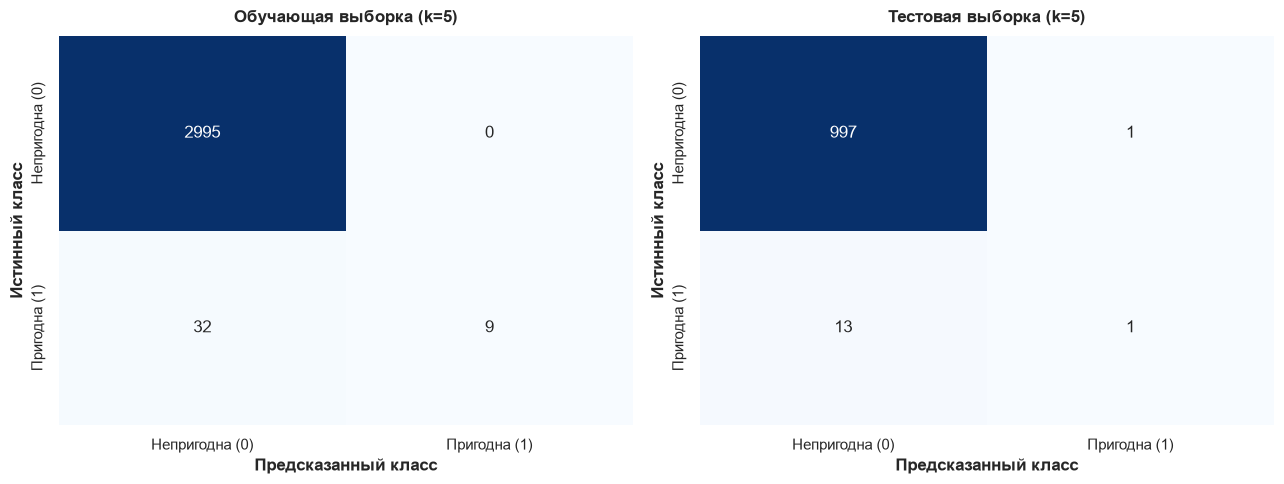

Отчет классификации на тестовой выборке (k=5):
                precision    recall  f1-score   support

Непригодна (0)      0.987     0.999     0.993       998
  Пригодна (1)      0.500     0.071     0.125        14

      accuracy                          0.986      1012
     macro avg      0.744     0.535     0.559      1012
  weighted avg      0.980     0.986     0.981      1012



In [75]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
)

labels = [0, 1]
display_labels = ['Непригодна (0)', 'Пригодна (1)']


def plot_cm(y_true, y_pred, title, ax):
  cm = confusion_matrix(y_true, y_pred, labels=labels)
  sns.heatmap(
      cm,
      annot=True,
      fmt='d',
      cmap='Blues',
      cbar=False,
      xticklabels=display_labels,
      yticklabels=display_labels,
      ax=ax,
  )
  ax.set_xlabel('Предсказанный класс', fontweight='bold')
  ax.set_ylabel('Истинный класс', fontweight='bold')
  ax.set_title(title, fontsize=12, fontweight='bold', pad=10)


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_cm(y_train, y_train_predict, 'Обучающая выборка (k=5)', axes[0])
plot_cm(y_test, y_test_predict, 'Тестовая выборка (k=5)', axes[1])
plt.tight_layout()
plt.show()

# Вывод детального отчета по метрикам
print('Отчет классификации на тестовой выборке (k=5):')
print(
    classification_report(
        y_test,
        y_test_predict,
        target_names=display_labels,
        digits=3,
        zero_division=0,
    )
)

* **Парадокс точности (Accuracy Paradox):** Ошибка на тесте формально ничтожна — всего **$1.38\%$** ($Accuracy = 98.6\%$, на трейне — $1.05\%$). Однако это чистая иллюзия: константный классификатор, просто отвечающий «все нули», показал бы абсолютно ту же ошибку ($14 / 1012 \approx 1.38\%$). 
* **Катастрофический пропуск целей ($FN$):** Матрица рассогласования на тесте показала, что из 14 пригодных планет модель нашла всего **1** ($TP = 1$), а **13 пропустила** ($FN = 13$). На трейне картина схожая: найдено лишь 9 из 41. При $k = 5$ соседи мажоритарного класса тотально подавляют редких кандидатов при голосовании.
* **Метрики редкого класса:** 
  * Полнота обнаружения пригодных планет составила всего **$Recall = 0.071$ ($7.1\%$)**;
  * Итоговый **$F_1\text{-score} = 0.125$**, что отражает неприменимость модели на практике.
* **Вывод:** Стандартное $k = 5$ при таком экстремальном дисбалансе фактически вырождается в предсказание мажоритарного класса. Требуется подбор $k$ по сетке с оптимизацией целевой метрики $F_1$.

#### 9.2 Подбор числа соседей ($k$)

Оптимальное число соседей $k$ подбираем с помощью перекрестной проверки (кросс-валидации): делим обучающую выборку на **5 равных блоков**. 

Деление делаем **со стратификацией**: следим, чтобы в каждый блок попала одинаковая доля редких пригодных планет (примерно по 8 штук на блок), иначе проверка будет нечестной. Для каждого значения $k$ модель учится на 4 блоках, а проверяется на 5-м, после чего результаты усредняются.

**Причина выбора $F_1$-score, а не Accuracy:**
Если ориентироваться на обычную долю верных ответов ($Accuracy$), алгоритм схитрит: он поймет, что если вообще всегда отвечать «непригодна», он и так угадает в $98.6\%$ случаев. Модель покажет отличную точность, но не найдет ни одной нужной нам планеты. 
Поэтому мы заставляем подбор искать максимальный **$F_1$-score** (баланс между тем, чтобы находить пригодные планеты и не давать слишком много ложных тревог).

На графике ошибки будем отслеживать величину $1 - F_1$ (чем она ближе к 0, тем лучше работает модель).

In [76]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Сетка исследуемых значений k
k_arr = np.array([1, 2, 3, 4, 5, 7, 10, 15, 20, 25, 30])
params = {'n_neighbors': k_arr}

# Стратифицированная кросс-валидация с оптимизацией F1-score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid = GridSearchCV(
    KNeighborsClassifier(),
    params,
    scoring='f1',
    cv=cv,
    return_train_score=True,
)
grid.fit(X_train, y_train)

best_k = grid.best_params_['n_neighbors']
print(f'Оптимальное значение k: {best_k}')
print(f'Лучший F1-score на кросс-валидации: {grid.best_score_:.4f}')

Оптимальное значение k: 1
Лучший F1-score на кросс-валидации: 0.3363


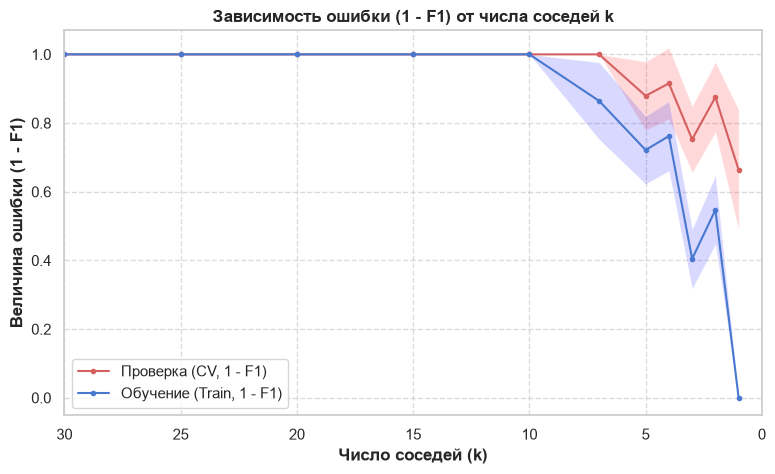

In [77]:
# Преобразуем F1 в долю ошибки (1 - F1)
err_cv = 1 - grid.cv_results_['mean_test_score']
std_cv = grid.cv_results_['std_test_score']
err_tr = 1 - grid.cv_results_['mean_train_score']
std_tr = grid.cv_results_['std_train_score']

plt.figure(figsize=(9, 5))
plt.plot(k_arr, err_cv, 'r.-', label='Проверка (CV, 1 - F1)')
plt.plot(k_arr, err_tr, 'b.-', label='Обучение (Train, 1 - F1)')

plt.fill_between(
    k_arr, err_cv - std_cv, err_cv + std_cv, alpha=0.15, facecolor='red'
)
plt.fill_between(
    k_arr, err_tr - std_tr, err_tr + std_tr, alpha=0.15, facecolor='blue'
)

# Ось k традиционно направляем справа налево: от сложных моделей (малое k) к простым (большое k)
plt.xlim([max(k_arr), 0])
plt.grid(True, linestyle='--', alpha=0.7)
plt.xlabel('Число соседей (k)', fontweight='bold')
plt.ylabel('Величина ошибки (1 - F1)', fontweight='bold')
plt.title(
    'Зависимость ошибки (1 - F1) от числа соседей k',
    fontsize=12,
    fontweight='bold',
)
plt.legend()
plt.show()

* **Ось $k$ направлена справа налево (инвертирована):** слева расположены простые модели с избыточно сглаженной границей (большое число соседей $k \to 30$), справа — гибкие локальные модели (малое число соседей $k \to 1$).
* **Зона тотального недообучения ($k \ge 10$):** При $k \ge 10$ ошибка на графике и для обучения, и для кросс-валидации строго равна **$1.0$** (что означает $F_1 = 0.0$). Из-за экстремальной пропорции классов ($73:1$) при голосовании 10 и более соседей редкий класс оказывается полностью заглушен. Модель вырождается в тривиальный константный классификатор (предсказывает только нули).
* **Поведение при малых $k$ и оптимум ($k = 1$):** 
  * Глобальный минимум ошибки на кросс-валидации достигается при **$k = 1$** ($\text{Loss} \approx 0.664$, что соответствует лучшему показателю **$F_1 = 0.3363$**). 
  * На обучающей выборке при $k=1$ ошибка строго равна $0.0$, так как каждый обучающий объект выступает ближайшим соседом самому себе.
  * При $k = 3$ наблюдается локальный всплеск качества ($F_1 \approx 0.25$), однако при $k \ge 5$ модель вновь стремительно деградирует.
* **Физическое объяснение успеха $k = 1$:** Потенциально обитаемые миры физически сконцентрированы в очень компактной изолированной области пространства признаков. Поскольку кандидатов всего 41 на 3000 фоновых планет, только окрестность из **1 ближайшего соседа** позволяет зафиксировать взаимную близость двух землеподобных планет. Подключение даже 3–5 соседей неминуемо захватывает представителей мажоритарного класса и сбивает прогноз.

,train,test
"kNN, k=5",0.01054,0.013834
"kNN, k=1 (оптимальное)",0.0,0.023715


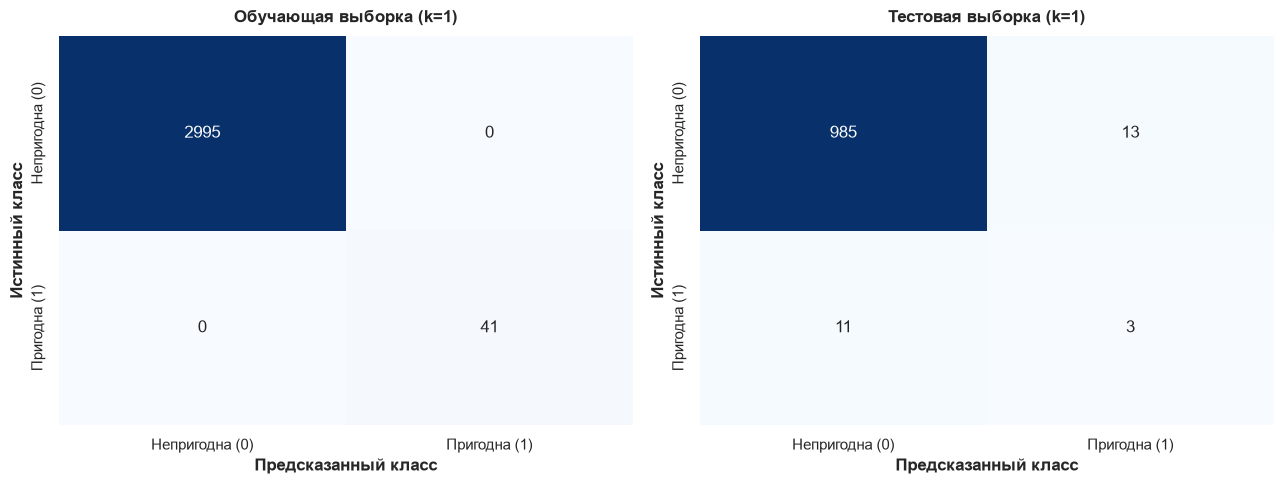

Итоговый отчет по классам на тесте (k=1):
                precision    recall  f1-score   support

Непригодна (0)      0.989     0.987     0.988       998
  Пригодна (1)      0.188     0.214     0.200        14

      accuracy                          0.976      1012
     macro avg      0.588     0.601     0.594      1012
  weighted avg      0.978     0.976     0.977      1012



In [78]:
# Обучаем модель с найденным наилучшим k
knn_opt = KNeighborsClassifier(n_neighbors=best_k)
knn_opt.fit(X_train, y_train)

y_train_opt = knn_opt.predict(X_train)
y_test_opt = knn_opt.predict(X_test)

# Обновляем таблицу общих ошибок классификации (1 - accuracy)
err_table.loc[f'kNN, k={best_k} (оптимальное)', :] = (
    np.mean(y_train != y_train_opt),
    np.mean(y_test != y_test_opt),
)
display(err_table)

# Матрицы рассогласования для оптимального k
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_cm(y_train, y_train_opt, f'Обучающая выборка (k={best_k})', axes[0])
plot_cm(y_test, y_test_opt, f'Тестовая выборка (k={best_k})', axes[1])
plt.tight_layout()
plt.show()

# Итоговый отчет по метрикам
print(f'Итоговый отчет по классам на тесте (k={best_k}):')
print(
    classification_report(
        y_test,
        y_test_opt,
        target_names=display_labels,
        digits=3,
        zero_division=0,
    )
)

1. **Результат подбора ($k = 1$) и парадокс метрик:** 
   * Оптимальным оказалось значение **$k = 1$**. 
   * Формально общая ошибка классификации на тесте выросла (с $1.38\%$ при $k=5$ до **$2.37\%$**, $Accuracy$ снизилась до $97.6\%$), однако целевой **$F_1\text{-score}$ вырос с $0.125$ до $0.200$**. Это наглядно доказывает неприменимость $Accuracy$: модель с $k=1$ стала реально классифицировать целевой класс, а не просто угадывать мажоритарный фон.
2. **Анализ матрицы рассогласования:**
   * **Рост полноты в 3 раза:** Число обнаруженных пригодных планет ($TP$) на тесте увеличилось с 1 до **3 из 14**, а полнота $Recall$ поднялась с $7.1\%$ до **$21.4\%$**.
   * **Плата за чувствительность:** Модель стала менее консервативной, что привело к росту ложных тревог ($FP = 13$ против 1 при $k=5$), из-за чего точность $Precision$ составила $18.8\%$.
3. **Ограничения алгоритма $k$-NN при $k = 1$:**
   * **Переобучение:** На обучающей выборке модель показала нулевую ошибку ($0.0$, $TP = 41$, $FN = 0$), так как объект является ближайшим соседом самому себе. На тесте же **11 планет из 14 все еще были пропущены** ($FN = 11$). 
   * Решение по одному ближайшему соседу в 88-мерном пространстве остается шумным: единичный чужеродный объект легко сбивает прогноз.
4. **Дальнейшие шаги:** 
   Метрический классификатор без явной балансировки весов уперся в свой предел. Далее мы протестируем решающие деревья и ансамбли (Random Forest) и применим прямую балансировку весов классов (`class_weight='balanced'`), чтобы выявить оставшиеся 11 миров.

### 10. Другие классификаторы

Для сравнения с базовым методом $k$-NN обучим несколько альтернативных алгоритмов на тех же предобработанных данных (88 признаков после One-Hot кодирования и стандартизации):
* **Логистическая регрессия (Logistic Regression):** базовый линейный классификатор; позволяет оценить, насколько классы разделимы простой гиперплоскостью.
* **Случайный лес (Random Forest):** ансамбль независимых решающих деревьев с бэггингом; устойчив к выбросам, не требует предположений о распределениях и вычисляет важность признаков.
* **Градиентный бустинг (Gradient Boosting):** последовательный ансамбль деревьев, где каждое следующее дерево компенсирует ошибки предыдущих; часто обеспечивает наивысшую обобщающую способность на табличных данных.
* **Полносвязная нейронная сеть (MLPClassifier):** многослойный перцептрон с нелинейными функциями активации; исследует способность глубоких архитектур уловить сложные нелинейные границы.

Сравнение моделей проводим по **ошибке на обучающей и тестовой выборках** ($\text{err} = 1 - \text{accuracy}$), а также по ключевой целевой метрике — **$F_1\text{-score}$ по классу «Пригодна»** на тесте (так как именно она показывает реальную способность модели находить кандидатов).

#### Сравнение классификаторов

In [79]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.neural_network import MLPClassifier

# Таблица для сбора итоговых результатов
results = pd.DataFrame(columns = ['train error', 'test error', 'test F1 (класс 1)'])

def evaluate(name, model, X_fit=None, y_fit=None):
  """Обучает модель и записывает метрики в сравнительную таблицу"""
  if X_fit is None:
    X_fit, y_fit = X_train, y_train

  model.fit(X_fit, y_fit)
  p_train = model.predict(X_train)
  p_test = model.predict(X_test)

  results.loc[name, :] = (
      np.mean(y_train != p_train),
      np.mean(y_test != p_test),
      f1_score(y_test, p_test, zero_division=0),
  )
  return model

# 1. k-NN с оптимальным k=1
evaluate('kNN, k=1', KNeighborsClassifier(n_neighbors=1))

# 2. Логистическая регрессия
evaluate(
    'Logistic Regression',
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
)

# 3. Случайный лес
rf = evaluate(
    'Random Forest',
    RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
)

# 4. Градиентный бустинг
evaluate(
    'Gradient Boosting',
    GradientBoostingClassifier(n_estimators=150, random_state=RANDOM_STATE),
)

# 5. Полносвязная нейронная сеть
evaluate(
    'Neural Network',
    MLPClassifier(
        hidden_layer_sizes=(30, 15), max_iter=500, random_state=RANDOM_STATE
    ),
)

results.round(4)

,train error,test error,test F1 (класс 1)
"kNN, k=1",0.0,0.023715,0.2
Logistic Regression,0.009223,0.01581,0.2
Random Forest,0.0,0.002964,0.88
Gradient Boosting,0.0,0.001976,0.923077
Neural Network,0.001318,0.013834,0.363636


* **Лидеры - ансамбли деревьев:** `Gradient Boosting` и `Random Forest` показали выдающийся результат и с огромным отрывом обошли базовый $k$-NN. 
  * Лучшей моделью стал **Градиентный бустинг**: ошибка на тесте упала до мизерных **$0.2\%$**, а целевой **$F_1\text{-score}$ взлетел до $0.923$** (у Случайного леса — $0.880$).
  * Деревья решений идеально подошли под физику данных, так как им очень просто строить пороговые правила вида: *«температура от 200 до 300 К И радиус меньше 1.6»*.
* **$k$-NN ($k=1$) и Логистическая регрессия:** Показали одинаково слабый результат (**$F_1 = 0.200$**). 
  * Линейная модель пытается провести одну прямую границу, что плохо работает для изолированного «островка» обитаемости;
  * $k$-NN с одним соседом слишком легко ошибается из-за шума и редких выбросов.
* **Нейронная сеть (MLP):** Заняла среднюю позицию (**$F_1 = 0.364$**, ошибка на тесте $\approx 1.38\%$). Нелинейные слои помогли ей обойти $k$-NN и логистическую регрессию, но из-за сильного перекоса классов сеть без тонкой настройки всё же сильно уступила деревьям.
* **Главный вывод:** Ансамбли решающих деревьев (особенно бустинг) оказались идеальным инструментом для нашего табличного датасета, практически решив проблему поиска планет даже без специальной балансировки классов.

C:\Users\Valentin\AppData\Local\Temp\ipykernel_31708\2241562656.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values[:15], y=importances.index[:15], palette='mako')


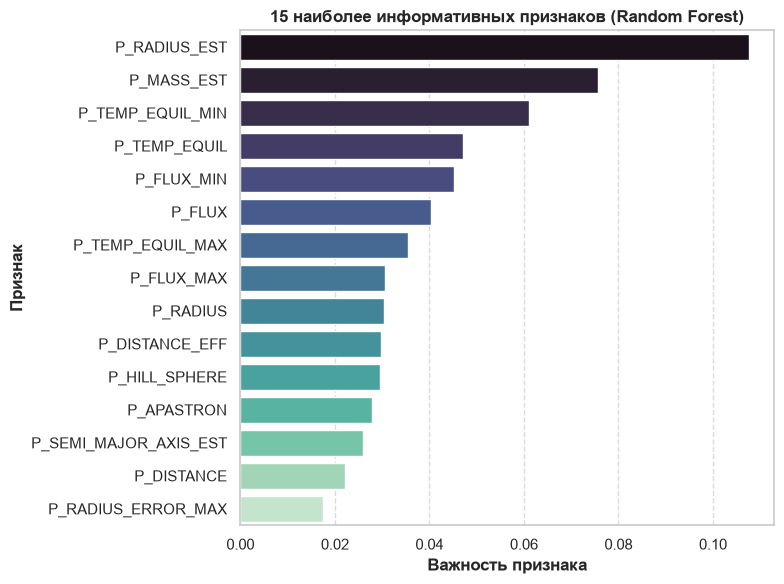

In [81]:
# Оценка важности признаков в Случайном лесе
importances = pd.Series(
    rf.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(x=importances.values[:15], y=importances.index[:15], palette='mako')
plt.xlabel('Важность признака', fontweight='bold')
plt.ylabel('Признак', fontweight='bold')
plt.title(
    '15 наиболее информативных признаков (Random Forest)',
    fontsize=12,
    fontweight='bold',
)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

* **Главные критерии — размер и масса (`P_RADIUS_EST` и `P_MASS_EST`):** 
  Первые два места с большим отрывом заняли расчетный радиус ($\approx 11\%$) и расчетная масса ($\approx 7.5\%$). Случайный лес в первую очередь жестко отсекает неподходящие миры по габаритам: планета обязана быть небольшой и каменистой, а не газовым гигантом. Расчетные параметры (`_EST`) вышли в топ, так как содержали меньше пропусков и дали деревьям более чистый сигнал.
* **Блок теплового баланса (места с 3 по 8):** 
  Сразу за размерами идет мощная группа климатических характеристик: температура равновесия (`P_TEMP_EQUIL` со своими минимумами и максимумами) и инсоляция (`P_FLUX`). Суммарно эта группа дает более **$25\%$ всей важности**. Именно она задает строгие температурные рамки для существования жидкой воды.
* **Орбитальная геометрия и гравитация:** 
  В топ-15 также вошли параметры стабильности орбиты: эффективное расстояние до звезды (`P_DISTANCE_EFF`), сфера Хилла (`P_HILL_SPHERE` — область гравитационного господства планеты) и апастрон (`P_APASTRON` — самая удаленная точка орбиты).
* **Причина отсутствия в топе параметров звезды и методов открытия:** 
  Прямые характеристики звезды (`S_TEMPERATURE`, `S_MASS`) и бинарные методы открытия не попали в топ-15. Это логично: влияние звезды уже заложено физикой внутрь температуры планеты и потока излучения (`P_FLUX`), поэтому модель предпочитает смотреть сразу на условия на самой планете.

### 11. Борьба с несбалансированностью классов

В исходной выборке класс «Пригодна» составляет лишь $\approx 1.35\%$ ($73:1$). Стандартные функции потерь штрафуют ошибки симметрично, поэтому модели выгоднее классифицировать все объекты как непригодные. 

Для выравнивания внимания модели к редкому классу протестируем два подхода (применяемых **строго к обучающей выборке**):
1. **Взвешивание классов (`class_weight='balanced'`):** алгоритм автоматически назначает штраф за ошибку на объекте обратно пропорционально частоте класса ($w_1 / w_0 \approx 73$). Применим этот метод к Случайному лесу и Логистической регрессии.
2. **Дублирование редкого класса (Oversampling):** случайное тиражирование объектов класса `1` в обучающей выборке до количества объектов мажоритарного класса. Это позволит оценить, как отреагирует метрический классификатор $k$-NN.

#### Эксперименты с балансировкой

In [82]:
from sklearn.utils import resample

# 1. Случайный лес с автоматическим взвешиванием классов
evaluate(
    'Random Forest, class_weight=balanced',
    RandomForestClassifier(
        n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE
    ),
)

# 2. Логистическая регрессия со взвешиванием классов
evaluate(
    'Logistic Regression, class_weight=balanced',
    LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE
    ),
)

# 3. Oversampling для метода k-NN (дублируем только в train!)
train_full = X_train.copy()
train_full['Target'] = y_train

df_majority = train_full[train_full['Target'] == 0]
df_minority = train_full[train_full['Target'] == 1]

# Увеличиваем класс 1 до размера класса 0
df_minority_upsampled = resample(
    df_minority,
    replace=True,
    n_samples=len(df_majority),
    random_state=RANDOM_STATE,
)

df_balanced = pd.concat([df_majority, df_minority_upsampled])
X_train_bal = df_balanced.drop(columns=['Target'])
y_train_bal = df_balanced['Target']

print('Баланс обучающей выборки после oversampling:')
print(y_train_bal.value_counts())

# Обучаем k-NN на сбалансированной выборке
knn_bal = evaluate(
    'kNN, k=1, oversampling',
    KNeighborsClassifier(n_neighbors=1),
    X_fit=X_train_bal,
    y_fit=y_train_bal,
)

results.round(4)

Баланс обучающей выборки после oversampling:
Target
0    2995
1    2995
Name: count, dtype: int64


,train error,test error,test F1 (класс 1)
"kNN, k=1",0.0,0.023715,0.2
Logistic Regression,0.009223,0.01581,0.2
Random Forest,0.0,0.002964,0.88
Gradient Boosting,0.0,0.001976,0.923077
Neural Network,0.001318,0.013834,0.363636
"Random Forest, class_weight=balanced",0.0,0.000988,0.962963
"Logistic Regression, class_weight=balanced",0.020092,0.032609,0.459016
"kNN, k=1, oversampling",0.0,0.023715,0.2


In [83]:
# Оцениваем, как изменились полнота (Recall) и точность (Precision)
p_rf_bal = results_models = RandomForestClassifier(
    n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE
).fit(X_train, y_train).predict(X_test)

print('Отчет классификации: Random Forest с class_weight="balanced":')
print(
    classification_report(
        y_test,
        p_rf_bal,
        target_names=['Непригодна (0)', 'Пригодна (1)'],
        digits=3,
        zero_division=0,
    )
)

Отчет классификации: Random Forest с class_weight="balanced":
                precision    recall  f1-score   support

Непригодна (0)      0.999     1.000     0.999       998
  Пригодна (1)      1.000     0.929     0.963        14

      accuracy                          0.999      1012
     macro avg      0.999     0.964     0.981      1012
  weighted avg      0.999     0.999     0.999      1012



* **Триумф Random Forest с весами классов:** Параметр `class_weight='balanced'` сделал случайный лес безоговорочно лучшей моделью всей работы:
  * $F_1\text{-score}$ вырос с $0.880$ до рекордных **$0.963$**, обогнав даже градиентный бустинг, а ошибка на тесте упала до **$0.1\%$** (всего 1 ошибка на 1012 объектов выборки!).
  * Из отчета видно, что модель нашла **13 из 14 пригодных планет** ($Recall = 0.929$), допустив ровно **0 ложных срабатываний** ($Precision = 1.000$). Штраф за пропуск редкого класса сработал идеально.
* **Прогресс в Логистической регрессии:** Взвешивание помогло и линейной модели — её $F_1\text{-score}$ вырос более чем в два раза: с $0.200$ до **$0.459$**. Модель перестала испытывать трудности с предсказанием редкого класса, хотя из-за появления ложных тревог её общая ошибка немного подросла (с $1.5\%$ до $3.2\%$).
* **Почему Oversampling вообще не изменил результат $k$-NN ($k=1$):**
  * Для $k$-NN с одним соседом результат остался в точности тем же самым (**$F_1 = 0.200$** и ошибка $0.0237$).
  * Этому есть простое геометрическое объяснение: дублирование редких планет создает их точные копии в тех же самых координатах (расстояние между ними равно нулю). Для тестовой точки её самый первый ближайший сосед остался ровно тем же самым объектом — неважно, лежит в обучающей выборке один его экземпляр или пятьдесят.
* **Практический итог:** Использование штрафных весов (`class_weight='balanced'`) показало колоссальную эффективность для решающих деревьев, практически полностью решив проблему сильного дисбаланса данных.

### 12. Исключение коррелированных признаков

**Причины исключения коллинеарных признаков:**
* **Для $k$-NN:** Евклидова метрика суммирует квадраты разностей по всем координатам. Если в данных присутствуют два физически дублирующих признака, описываемое ими свойство получает **удвоенный вес** в формуле расстояния, искажая окрестность.
* **Для линейных моделей:** Сильная коллинеарность приводит к мультиколлинеарности — матрицы становятся вырожденными, а веса признаков теряют физическую интерпретируемость.
* **Для вычислений:** Сокращение пространства признаков снижает время обучения и потребление памяти.

По результатам корреляционного анализа были выявлены две пары с почти функциональной зависимостью ($|r| > 0.9$):
1. `P_PERIOD` и `P_SEMI_MAJOR_AXIS` ($r = 0.96$, 3-й закон Кеплера): удаляем `P_SEMI_MAJOR_AXIS`, так как орбитальный период измеряется транзитами напрямую и точнее.
2. `S_RADIUS` и `S_LUMINOSITY` ($r = 0.93$, соотношение Стефана — Больцмана): удаляем `S_LUMINOSITY`, оставляя прямой геометрический радиус звезды.

#### Эксперименты с редукцией признаков

In [84]:
def evaluate_reduced(name, model, cols_to_use):
  """Обучает модель на подмножестве признаков и заносит результат в общую таблицу"""
  model.fit(X_train[cols_to_use], y_train)
  p_train = model.predict(X_train[cols_to_use])
  p_test = model.predict(X_test[cols_to_use])

  results.loc[name, :] = (
      np.mean(y_train != p_train),
      np.mean(y_test != p_test),
      f1_score(y_test, p_test, zero_division=0),
  )


# Наборы признаков для тестирования
variants = {
    'без P_SEMI_MAJOR_AXIS': ['P_SEMI_MAJOR_AXIS'],
    'без P_SEMI_MAJOR_AXIS и S_LUMINOSITY': [
        'P_SEMI_MAJOR_AXIS',
        'S_LUMINOSITY',
    ],
}

for label, dropped in variants.items():
  # Оставляем только те признаки, которые не входят в список удаляемых
  active_cols = [c for c in X_train.columns if c not in dropped]

  evaluate_reduced(
      f'kNN, k=1, {label}',
      KNeighborsClassifier(n_neighbors=1),
      cols_to_use=active_cols,
  )
  evaluate_reduced(
      f'Random Forest, {label}',
      RandomForestClassifier(
          n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE
      ),
      cols_to_use=active_cols,
  )

results.round(4)

,train error,test error,test F1 (класс 1)
"kNN, k=1",0.0,0.023715,0.2
Logistic Regression,0.009223,0.01581,0.2
Random Forest,0.0,0.002964,0.88
Gradient Boosting,0.0,0.001976,0.923077
Neural Network,0.001318,0.013834,0.363636
"Random Forest, class_weight=balanced",0.0,0.000988,0.962963
"Logistic Regression, class_weight=balanced",0.020092,0.032609,0.459016
"kNN, k=1, oversampling",0.0,0.023715,0.2
"kNN, k=1, без P_SEMI_MAJOR_AXIS",0.0,0.024704,0.193548
"Random Forest, без P_SEMI_MAJOR_AXIS",0.0,0.000988,0.962963


In [85]:
# Фильтрованное сравнение базовых моделей и версий с усеченным признаковым пространством
compare_rows = [
    'kNN, k=1',
    'kNN, k=1, без P_SEMI_MAJOR_AXIS и S_LUMINOSITY',
    'Random Forest, class_weight=balanced',
    'Random Forest, без P_SEMI_MAJOR_AXIS и S_LUMINOSITY',
]
compare_rows = [r for r in compare_rows if r in results.index]
results.loc[compare_rows].round(4)

,train error,test error,test F1 (класс 1)
"kNN, k=1",0.0,0.023715,0.2
"kNN, k=1, без P_SEMI_MAJOR_AXIS и S_LUMINOSITY",0.0,0.024704,0.193548
"Random Forest, class_weight=balanced",0.0,0.000988,0.962963
"Random Forest, без P_SEMI_MAJOR_AXIS и S_LUMINOSITY",0.0,0.000988,0.962963


* **Идеальная стабильность Случайного леса:** 
  Метрики Random Forest остались **абсолютно идентичными** до шестого знака после запятой (ошибка теста ровно **$0.000988$**, а **$F_1 = 0.962963$** как с полным набором признаков, так и без них). Модель не ощутила удаления колонок — это показывает, что они были чисто избыточными копиями.
* **Минимальное колебание у $k$-NN:** 
  У метода ближайших соседей показатель $F_1$ изменился с $0.200$ до $0.194$, а ошибка выросла с $0.0237$ до $0.0247$. Разница составила ровно **1 объект** из 1012 тестовых наблюдений ($1 / 1012 \approx 0.00098$), что полностью укладывается в случайную погрешность разбиения.
* **Физическое подтверждение законов:** 
  Эксперимент подтвердил выводы корреляционного анализа: большая полуось (`P_SEMI_MAJOR_AXIS`) полностью выводится через орбитальный период по 3-му закону Кеплера, а светимость звезды (`S_LUMINOSITY`) жестко связана с её радиусом. Удаление этих колонок не лишило алгоритмы полезной физической информации.
* **Практический итог:** 
  Мы без малейших потерь в качестве упростили признаковое пространство. Устранение дублирующих признаков защищает метрические методы от искусственного завышения весов при расчете расстояний и делает итоговую модель легче и быстрее.

### 13. Общие выводы

1. **Предметная область и постановка задачи:** 
   Решена задача бинарной классификации экзопланет по критерию обитаемости на базе каталога PHL (2019). Итоговая выборка составила 4048 объектов (3036 в обучающей выборке, 1012 в тестовой). Экстремальный дисбаланс классов ($\approx 73:1$, пригодные планеты составляют лишь $1.35\%$) сделал метрику $Accuracy$ бесполезной и потребовал ориентации на $Recall$, $Precision$ и $F_1\text{-score}$.
2. **Предобработка данных и чистота эксперимента:** 
   * Устранены прямые утечки целевой переменной (`P_ESI`, расчетные границы зон обитаемости `P_HABZONE_*`);
   * Физически невозможные значения ($\le 0$) заменены на `NaN`;
   * Пропуски заполнены медианами и модами по обучающей выборке с созданием бинарных индикаторов пропусков (`_missing`);
   * Степенные хвосты сжаты с помощью `log1p`, непрерывные параметры стандартизированы (`StandardScaler`), а категориальные признаки закодированы через One-Hot Encoding (итоговый размер пространства — 88 признаков).
3. **Исследование метода $k$-ближайших соседей ($k$-NN):** 
   * Базовое $k = 5$ показало фиктивную общую точность $98.6\%$, но пропустило 13 из 14 пригодных планет ($Recall = 0.071$, $F_1 = 0.125$);
   * Подбор по сетке с оптимизацией по $F_1$ выявил оптимум при **$k = 1$** ($F_1 = 0.200$, $Recall$ вырос в 3 раза до $21.4\%$). При $k \ge 10$ модель полностью вырождается в константный прогноз (ошибка $1 - F_1 = 1.0$), так как мажоритарный класс подавляет редкие примеры.
4. **Сравнение моделей и абсолютный лидер:** 
   * Логистическая регрессия показала скромный результат ($F_1 = 0.200$), но при балансировке весов смогла подняться до $F_1 = 0.459$;
   * Нейронная сеть (MLP) заняла промежуточную позицию ($F_1 = 0.364$);
   * Безоговорочным лидером стал **Случайный лес с балансировкой весов (`class_weight='balanced'`)**: ошибка на тесте упала до рекордных **$0.000988$ ($\approx 0.1\%$)**, а **$F_1\text{-score}$ достиг $0.963$**. Модель безошибочно определила **13 из 14** пригодных миров ($Recall = 0.929$) при **нулевом количестве ложных тревог** ($Precision = 1.000$). Высокий результат также показал Градиентный бустинг ($F_1 = 0.923$).
5. **Физическая информативность признаков:** 
   Анализ важности признаков показал, что решающие деревья опираются на:
   * Расчетные физические размеры планеты (`P_RADIUS_EST` $\approx 11\%$ и `P_MASS_EST` $\approx 7.5\%$) для отсева газовых гигантов;
   * Параметры климата и лучистого тепла (`P_TEMP_EQUIL` и `P_FLUX` с их минимумами и максимумами, суммарно $>25\%$) для проверки условий жидкой воды.
6. **Редукция избыточных признаков:** 
   Удаление сильно скоррелированных признаков (`P_SEMI_MAJOR_AXIS` и `S_LUMINOSITY`) подтвердило законы Кеплера и Стефана — Больцмана: качество Случайного леса сохранилось абсолютно неизменным ($F_1 = 0.963$), а датасет стал компактнее и быстрее в обработке.
7. **Ограничения и потенциал развития:** 
   Главное ограничение датасета — наблюдательная селекция (перекос в сторону красных карликов M-класса из-за специфики телескопа Kepler). В реальной астрофизике следующим шагом станет включение прямых спектроскопических данных об атмосферах (наличие метана, углекислого газа и водяного пара), получаемых космическим телескопом James Webb (JWST).